# 1- Librairies

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [2]:
sns.set()

# 2 - Chargement des données

In [7]:
df = pd.read_csv('analyse_final.csv')

In [8]:
# Pays exclus de l'ACP et du clustering
pays_exclus = [
    "Brésil",
    "États-Unis d'Amérique",
    "Chine, continentale",
    "Inde",
    "Australie",
    "France"
]

# Conservation de la base complète
df_complet = df.copy()

# Exclusion des pays
df = df[~df["pays"].isin(pays_exclus)].reset_index(drop=True)

# Vérification
print(f"Pays avant exclusion : {len(df_complet)}")
print(f"Pays exclus : {len(df_complet) - len(df)}")
print(f"Pays conservés : {len(df)}")


Pays avant exclusion : 108
Pays exclus : 6
Pays conservés : 102


Notre étude initiale porte sur 108 pays, représentant environ 82,8 % de la population mondiale en 2017.

Avant de procéder à l'ACP et au clustering, nous choisissons d'exclure six pays. La France est retirée, car notre objectif consiste à identifier des marchés étrangers pour l'exportation.

Nous excluons également le Brésil, les États-Unis d'Amérique, la Chine continentale, l'Inde et l'Australie, qui présentaient des profils statistiques particulièrement atypiques dans nos premières analyses.

Leur poids sur certaines variables pouvait fortement influencer les axes factoriels et conduire à la formation de groupes de seulement un ou deux pays. Leur exclusion vise donc à mieux différencier les profils des autres marchés étudiés.

Cette sélection ne signifie pas que ces pays sont dépourvus de potentiel commercial, mais qu'ils nécessiteraient une analyse spécifique.

L'ACP et les méthodes de clustering porteront ainsi sur 102 pays. La couverture démographique de l'étude initiale reste de 82,8 %, tandis que celle du sous-ensemble analysé est nécessairement plus faible.

In [9]:
df.head()

,pays,volailles_dispo_alimentaire_kcal_pers_j,volailles_dispo_interieure,volailles_exportations,volailles_importations,volailles_production,population,continent,stabilite_politique,distance,pib_habitant,surface_bio_1000_ha,inflation_alimentaire
0,Afrique du Sud,143.0,2118.0,63.0,514.0,1667.0,57009756,Afrique,-0.28,9353.5520,14574.0,41.38,6.90
1,Albanie,85.0,47.0,0.0,38.0,13.0,2884169,Europe,0.38,1603.5340,15359.0,0.55,3.91
2,Algérie,22.0,277.0,0.0,2.0,275.0,41389189,Afrique,-0.92,1340.3900,15428.0,0.77,5.04
3,Allemagne,71.0,1739.0,646.0,842.0,1514.0,82658409,Europe,0.59,439.8984,61866.0,1138.30,2.76
4,Arabie saoudite,151.0,1435.0,10.0,722.0,616.0,33101178,Asie,-0.58,4694.5000,57943.0,17.10,-0.82


In [10]:
print(f"Le DataFrame utilisé pour notre analyse comporte {df.shape[0]} observations et {df.shape[1]} colonnes.")

Le DataFrame utilisé pour notre analyse comporte 102 observations et 13 colonnes.


In [11]:
print(f"Il a été préparé dans un différent notebook. Il a déjà été nettoyé et comporte {df.duplicated().sum()} doublons et {df.isnull().sum().sum()} valeurs nulles.")

Il a été préparé dans un différent notebook. Il a déjà été nettoyé et comporte 0 doublons et 0 valeurs nulles.


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 13 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   pays                                     102 non-null    object 
 1   volailles_dispo_alimentaire_kcal_pers_j  102 non-null    float64
 2   volailles_dispo_interieure               102 non-null    float64
 3   volailles_exportations                   102 non-null    float64
 4   volailles_importations                   102 non-null    float64
 5   volailles_production                     102 non-null    float64
 6   population                               102 non-null    int64  
 7   continent                                102 non-null    object 
 8   stabilite_politique                      102 non-null    float64
 9   distance                                 102 non-null    float64
 10  pib_habitant                             102 non-n

In [13]:
print("Voyons combien il y a de valeurs différentes par colonne.")
print(df.nunique())

Voyons combien il y a de valeurs différentes par colonne.
pays                                       102
volailles_dispo_alimentaire_kcal_pers_j     77
volailles_dispo_interieure                  94
volailles_exportations                      43
volailles_importations                      70
volailles_production                        91
population                                 102
continent                                    5
stabilite_politique                         86
distance                                   102
pib_habitant                               102
surface_bio_1000_ha                        101
inflation_alimentaire                       99
dtype: int64


In [14]:
df.describe()

,volailles_dispo_alimentaire_kcal_pers_j,volailles_dispo_interieure,volailles_exportations,volailles_importations,volailles_production,population,stabilite_politique,distance,pib_habitant,surface_bio_1000_ha,inflation_alimentaire
count,102.000000,102.000000,102.000000,102.000000,102.000000,1.020000e+02,102.000000,102.000000,102.000000,102.000000,102.00000
mean,77.196078,526.705882,77.696078,110.715686,514.078431,2.809595e+07,0.049314,5304.255996,28350.627451,222.796534,3.72902
std,48.610605,827.633314,213.450706,209.145711,800.627040,4.505468e+07,0.861537,4143.857664,23503.799997,481.970625,5.42078
min,2.000000,3.000000,0.000000,0.000000,0.000000,7.145800e+04,-2.410000,262.384500,1520.000000,0.010000,-3.33000
25%,44.750000,52.500000,0.000000,3.250000,41.250000,4.125791e+06,-0.500000,1701.371500,11106.000000,5.484500,0.42000
50%,70.500000,164.000000,4.000000,26.000000,131.000000,9.875108e+06,0.125000,4708.324500,20108.000000,41.585000,2.57000
75%,104.750000,618.500000,33.500000,114.500000,625.750000,3.496124e+07,0.680000,8784.594750,41624.250000,207.325000,4.42250
max,234.000000,4556.000000,1418.000000,1069.000000,4444.000000,2.646510e+08,1.590000,19263.880000,132170.000000,3180.000000,33.01000


# 3 - Préparation des données

Nous allons à présent séparer les données.

Commençons par préparer la matrice des données.

In [15]:
features = [
    'volailles_dispo_alimentaire_kcal_pers_j',
    'volailles_dispo_interieure',
    'volailles_exportations',
    'volailles_importations',
    'volailles_production',
    'population',
    'stabilite_politique',
    'distance',
    'pib_habitant',
    'surface_bio_1000_ha',
    'inflation_alimentaire'
]

X = df[features].values

In [16]:
print(type(X))
print(f"X est de type np.array.")

<class 'numpy.ndarray'>
X est de type np.array.


In [17]:
print(f"C'est une matrice de {X.shape[0]} lignes et {X.shape[1]} colonnes.")

C'est une matrice de 102 lignes et 11 colonnes.


Les noms des différents pays, les individus de notre analyse, seront stockés dans la variable names.

In [18]:
names = df['pays'].values

Et nous avons précédemment stocké  les noms des colonnes dans la variables features.

In [19]:
for colonne in features:
    print(colonne)

volailles_dispo_alimentaire_kcal_pers_j
volailles_dispo_interieure
volailles_exportations
volailles_importations
volailles_production
population
stabilite_politique
distance
pib_habitant
surface_bio_1000_ha
inflation_alimentaire


Nous sommes à présent prêt à effectuer notre ACP

# 4 - ACP

## 4.1 Standardisation

In [20]:
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

Il nous faut une moyenne à 0 et un écart type à 1

In [21]:
idx = ['mean', 'std']
pd.DataFrame(X_scaled).describe().round(2).loc[idx, :]

,0,1,2,3,4,5,6,7,8,9,10
mean,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [22]:
pd.DataFrame(X_scaled, columns=features).describe().round(2).loc[idx, :]

,volailles_dispo_alimentaire_kcal_pers_j,volailles_dispo_interieure,volailles_exportations,volailles_importations,volailles_production,population,stabilite_politique,distance,pib_habitant,surface_bio_1000_ha,inflation_alimentaire
mean,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 4.2 ACP

Nous allons travailler que sur l'ensemble des composantes : 

In [23]:
n_components = len(features)

In [24]:
pca = PCA(n_components=n_components)
pca.fit(X_scaled)

PCA(n_components=11)

In [25]:
pca.explained_variance_ratio_

array([0.29958172, 0.21048895, 0.12534565, 0.0986845 , 0.06774218,
       0.06174055, 0.05370401, 0.04276628, 0.02340543, 0.01609099,
       0.00044973])

In [26]:
scree = (pca.explained_variance_ratio_ * 100).round(2)

In [27]:
scree

array([29.96, 21.05, 12.53,  9.87,  6.77,  6.17,  5.37,  4.28,  2.34,
        1.61,  0.04])

In [28]:
print(f"La première composante capte donc {scree[0]} % de la variance. Les deux premières {(scree[0] + scree[1])} %.")

La première composante capte donc 29.96 % de la variance. Les deux premières 51.010000000000005 %.


Calculons à présent la somme calculée des composantes.

In [29]:
scree_cum = scree.cumsum().round()

Définisons une variable avec la liste de nos composantes:

In [30]:
x_list = range(1, n_components+1)
list(x_list)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

In [31]:
print('Variance par composante :')
for i, sc, cum in zip(x_list ,scree, scree_cum):
    print(f'  F{i} : {sc}%  (cumulé : {cum}%)')

Variance par composante :
  F1 : 29.96%  (cumulé : 30.0%)
  F2 : 21.05%  (cumulé : 51.0%)
  F3 : 12.53%  (cumulé : 64.0%)
  F4 : 9.87%  (cumulé : 73.0%)
  F5 : 6.77%  (cumulé : 80.0%)
  F6 : 6.17%  (cumulé : 86.0%)
  F7 : 5.37%  (cumulé : 92.0%)
  F8 : 4.28%  (cumulé : 96.0%)
  F9 : 2.34%  (cumulé : 98.0%)
  F10 : 1.61%  (cumulé : 100.0%)
  F11 : 0.04%  (cumulé : 100.0%)


## 4.2 Éboulis des valeurs propres

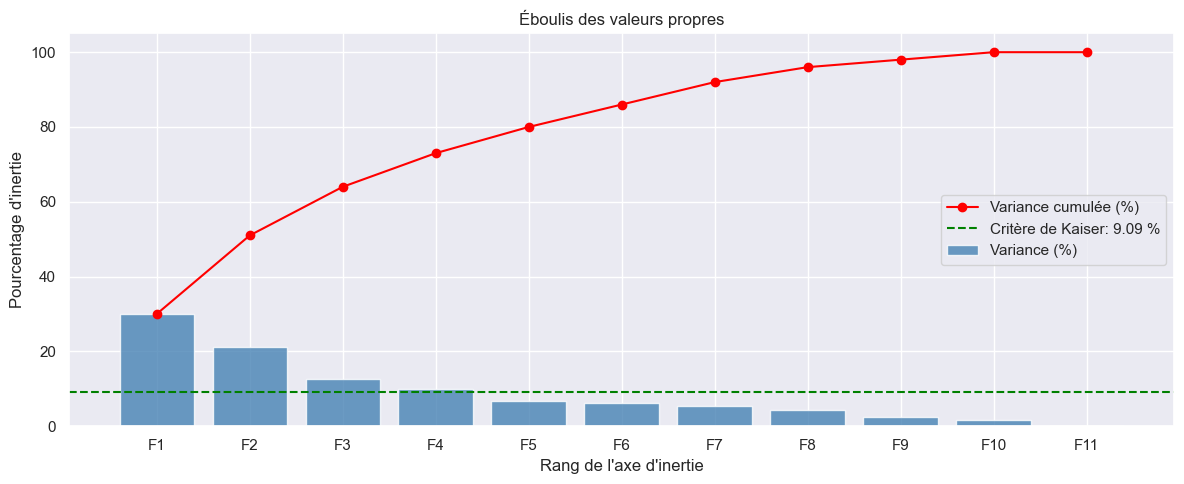

In [32]:
kaiser = 100 / n_components

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(x_list, scree, color='steelblue', alpha=0.8, label='Variance (%)')
ax.plot(x_list, scree_cum, c="red", marker='o', label='Variance cumulée (%)')
ax.axhline(y=kaiser, color='green', linestyle='--', label=f'Critère de Kaiser: {round(kaiser, 2)} %')

ax.set_xlabel("Rang de l'axe d'inertie")
ax.set_ylabel("Pourcentage d'inertie")

ax.set_xticks(list(x_list))
ax.set_xticklabels([f'F{i}' for i in x_list])


ax.legend(loc='center right')

plt.title('Éboulis des valeurs propres')
plt.tight_layout()
plt.show()

Afin de réduire la dimension de notre jeu de données tout en conservant une part importante de l'information initiale, nous étudions la variance expliquée par les composantes principales.

Le critère de Kaiser constitue un premier indicateur du nombre d'axes à retenir. Nous complétons cette approche par l'examen de la variance cumulée, afin de choisir une représentation suffisamment informative pour les analyses suivantes.

Nous retenons six composantes principales pour la suite de l'étude, sous réserve que la nouvelle variance cumulée confirme la pertinence de ce choix.

## 4.3 Components

Regardons à présent nos composantes.

In [33]:
pcs = pca.components_
pcs

array([[ 0.12052942,  0.52424758,  0.23348669,  0.36362185,  0.52490263,
         0.40292562, -0.1047983 ,  0.02876698,  0.07611294,  0.26064898,
         0.02207105],
       [-0.33327344,  0.05126682, -0.22027581, -0.16562527,  0.03341828,
         0.28890709, -0.5214309 ,  0.23263968, -0.55434536, -0.13120626,
         0.27429548],
       [ 0.51269479,  0.12326576, -0.36768012, -0.03456778,  0.04741022,
        -0.06330215,  0.19036501,  0.68064575, -0.16685348, -0.03583585,
        -0.2250985 ],
       [ 0.15017526, -0.04971673,  0.0343993 , -0.3396493 ,  0.03215766,
        -0.1493326 ,  0.14116378,  0.07841103, -0.02247653,  0.64092013,
         0.63066395],
       [ 0.20632707, -0.1366149 ,  0.70815104,  0.19794535, -0.00255308,
        -0.23236615, -0.02922692,  0.26978449, -0.22718057, -0.36658605,
         0.29063806],
       [ 0.23863407,  0.10140424, -0.44732814,  0.3902654 , -0.10088811,
         0.00881594,  0.00205254, -0.17949944,  0.22847167, -0.36485452,
         0.593

Mettons les dans un DataFrame.

In [34]:
pcs = pd.DataFrame(pcs)
pcs

,0,1,2,3,4,5,6,7,8,9,10
0,0.120529,0.524248,0.233487,0.363622,0.524903,0.402926,-0.104798,0.028767,0.076113,0.260649,0.022071
1,-0.333273,0.051267,-0.220276,-0.165625,0.033418,0.288907,-0.521431,0.232640,-0.554345,-0.131206,0.274295
2,0.512695,0.123266,-0.367680,-0.034568,0.047410,-0.063302,0.190365,0.680646,-0.166853,-0.035836,-0.225099
3,0.150175,-0.049717,0.034399,-0.339649,0.032158,-0.149333,0.141164,0.078411,-0.022477,0.640920,0.630664
4,0.206327,-0.136615,0.708151,0.197945,-0.002553,-0.232366,-0.029227,0.269784,-0.227181,-0.366586,0.290638
5,0.238634,0.101404,-0.447328,0.390265,-0.100888,0.008816,0.002053,-0.179499,0.228472,-0.364855,0.593770
6,0.596457,0.066745,0.001478,-0.289008,0.109040,-0.205318,-0.532823,-0.429322,-0.109742,-0.032964,-0.144442
7,0.079734,0.005848,0.126708,-0.626932,0.200689,0.439105,0.173739,0.059500,0.353438,-0.420959,0.124779
8,-0.156445,0.326881,-0.098398,-0.135608,0.384217,-0.323840,0.486078,-0.305348,-0.456089,-0.221774,0.037373
9,-0.320607,0.249924,-0.055294,-0.110260,0.262066,-0.577879,-0.330168,0.299201,0.457923,-0.087675,0.031607


In [35]:
pcs.columns = features
pcs.index = [f"F{i}" for i in x_list]
pcs.round(2)

,volailles_dispo_alimentaire_kcal_pers_j,volailles_dispo_interieure,volailles_exportations,volailles_importations,volailles_production,population,stabilite_politique,distance,pib_habitant,surface_bio_1000_ha,inflation_alimentaire
F1,0.12,0.52,0.23,0.36,0.52,0.40,-0.10,0.03,0.08,0.26,0.02
F2,-0.33,0.05,-0.22,-0.17,0.03,0.29,-0.52,0.23,-0.55,-0.13,0.27
F3,0.51,0.12,-0.37,-0.03,0.05,-0.06,0.19,0.68,-0.17,-0.04,-0.23
F4,0.15,-0.05,0.03,-0.34,0.03,-0.15,0.14,0.08,-0.02,0.64,0.63
F5,0.21,-0.14,0.71,0.20,-0.00,-0.23,-0.03,0.27,-0.23,-0.37,0.29
F6,0.24,0.10,-0.45,0.39,-0.10,0.01,0.00,-0.18,0.23,-0.36,0.59
F7,0.60,0.07,0.00,-0.29,0.11,-0.21,-0.53,-0.43,-0.11,-0.03,-0.14
F8,0.08,0.01,0.13,-0.63,0.20,0.44,0.17,0.06,0.35,-0.42,0.12
F9,-0.16,0.33,-0.10,-0.14,0.38,-0.32,0.49,-0.31,-0.46,-0.22,0.04
F10,-0.32,0.25,-0.06,-0.11,0.26,-0.58,-0.33,0.30,0.46,-0.09,0.03


Lire nos résultat est plus facile quand ils sont présentés sous la forme d'un DataFrame plutôt que sous celle d'un np.array. Mais nous n'avons pas besoin d'analyser toutes nos composantes. En effet, en s'appuyant sur le critère de Kaiser et sur la méthode du coude, nous décidons de ne garder que 6 composantes pour la suite de notre analyse.

In [36]:
n_comp = 6

pca = PCA(n_components=n_comp)
pca.fit(X_scaled)
X_proj = pca.transform(X_scaled)

print(f"Variance expliquée par les {n_comp} premières composantes:")
for i in range(n_comp):
    print(f"F{i+1} : {pca.explained_variance_ratio_[i] * 100 : .2f} %")
print(f"Total : {pca.explained_variance_ratio_.sum() * 100 : .2f} %")

Variance expliquée par les 6 premières composantes:
F1 :  29.96 %
F2 :  21.05 %
F3 :  12.53 %
F4 :  9.87 %
F5 :  6.77 %
F6 :  6.17 %
Total :  86.36 %


In [37]:
pcs = pca.components_
pcs = pd.DataFrame(pcs, columns = features, index = [f'F{i+1}' for i in range(n_comp)])
pcs.round(2)

,volailles_dispo_alimentaire_kcal_pers_j,volailles_dispo_interieure,volailles_exportations,volailles_importations,volailles_production,population,stabilite_politique,distance,pib_habitant,surface_bio_1000_ha,inflation_alimentaire
F1,0.12,0.52,0.23,0.36,0.52,0.40,-0.10,0.03,0.08,0.26,0.02
F2,-0.33,0.05,-0.22,-0.17,0.03,0.29,-0.52,0.23,-0.55,-0.13,0.27
F3,0.51,0.12,-0.37,-0.03,0.05,-0.06,0.19,0.68,-0.17,-0.04,-0.23
F4,0.15,-0.05,0.03,-0.34,0.03,-0.15,0.14,0.08,-0.02,0.64,0.63
F5,0.21,-0.14,0.71,0.20,-0.00,-0.23,-0.03,0.27,-0.23,-0.37,0.29
F6,0.24,0.10,-0.45,0.39,-0.10,0.01,0.00,-0.18,0.23,-0.36,0.59


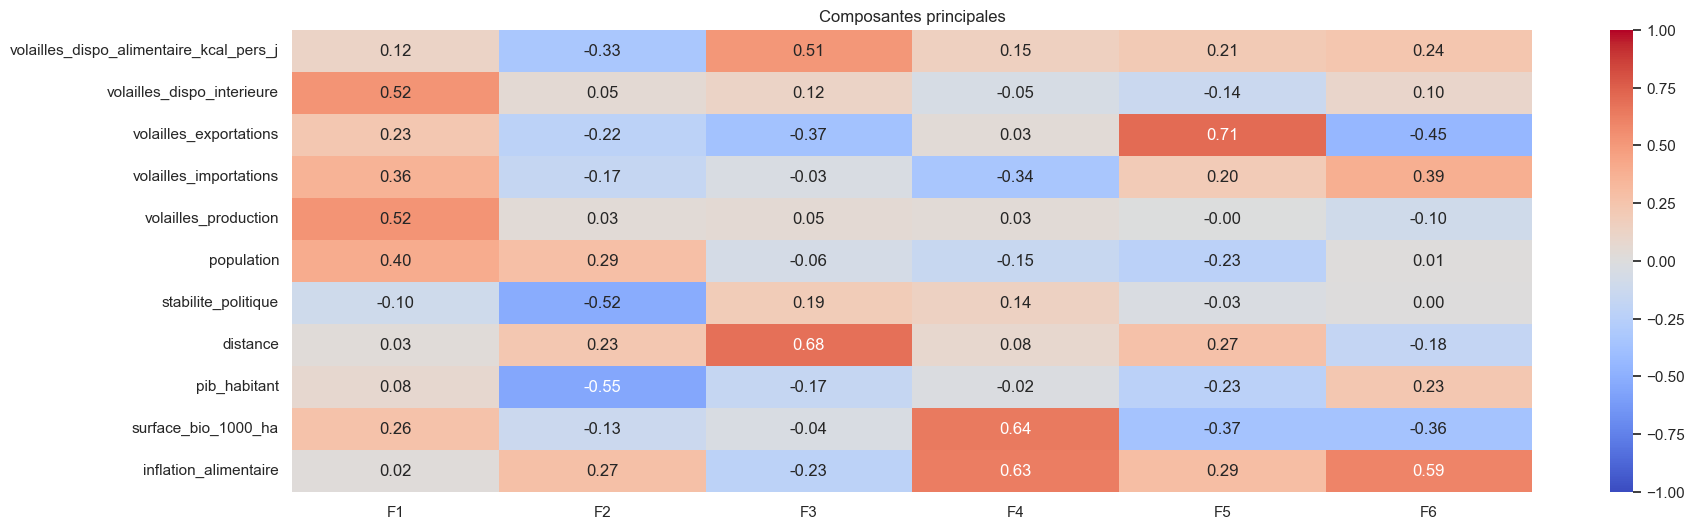

In [38]:
fig, ax = plt.subplots(figsize=(20, 6))

sns.heatmap(pcs.T, vmin = -1, vmax = 1, annot = True, cmap = 'coolwarm', fmt = '0.2f')

plt.title('Composantes principales')
plt.show()

**Observations**

- Les principales contributions à F1 sont, dans l'ordre décroissant de la force, volailles_dispo_interieure, volailles_production, volailles_exportations et volailles_dispo_alimentaire_kcal_pers_j pour les contribution positives.
- Les principales contributions à F2 sont, dans l'ordre décroissant de la force, inflation_alimentaire, population et distance pour les contributions positives, stabilite_politique et pib_habitant pour les contributions négatives.
-  Les principales contributions à F3 sont, dans l'ordre décroissant de la force, distance et surface_bio_1000_ha pour les contributions positives, volailles_importations et pib_habitant pour les contributions négatives.
-  Les principales contributions à F4 sont, dans l'ordre décroissant de la force, volailles_exportations, volailles_dispo_alimentaire_kcal_pers_j et inflation_alimentaire pour les contribution positives, volailles_importations, population et surface_bio_1000_ha pour les contributions négatives.
-  Les principales contributions à F5 sont, dans l'ordre décroissant de la force, inflation_alimentaire et surface_bio_1000_ha pour les contributions positives, la distance pour les contributions négatis.
ves.


## 4.4 Cercle des corrélations

In [39]:
def correlation_graph(pca, x_y, features) : 

    x,y = x_y

    fig, ax = plt.subplots(figsize=(10, 9))

    for i in range(0, pca.components_.shape[1]):
        ax.arrow(0,0, 
                pca.components_[x, i],  
                pca.components_[y, i],  
                head_width=0.07,
                head_length=0.07, 
                width=0.02, )


        plt.text(pca.components_[x, i] + 0.05,
                pca.components_[y, i] + 0.05,
                features[i])
        
    plt.plot([-1, 1], [0, 0], color='grey', ls='--')
    plt.plot([0, 0], [-1, 1], color='grey', ls='--')

    plt.xlabel('F{} ({}%)'.format(x+1, round(100*pca.explained_variance_ratio_[x],1)))
    plt.ylabel('F{} ({}%)'.format(y+1, round(100*pca.explained_variance_ratio_[y],1)))

    plt.title("Cercle des corrélations (F{} et F{})".format(x+1, y+1))

    an = np.linspace(0, 2 * np.pi, 100)
    plt.plot(np.cos(an), np.sin(an))  

    plt.axis('equal')
    plt.show(block=False)

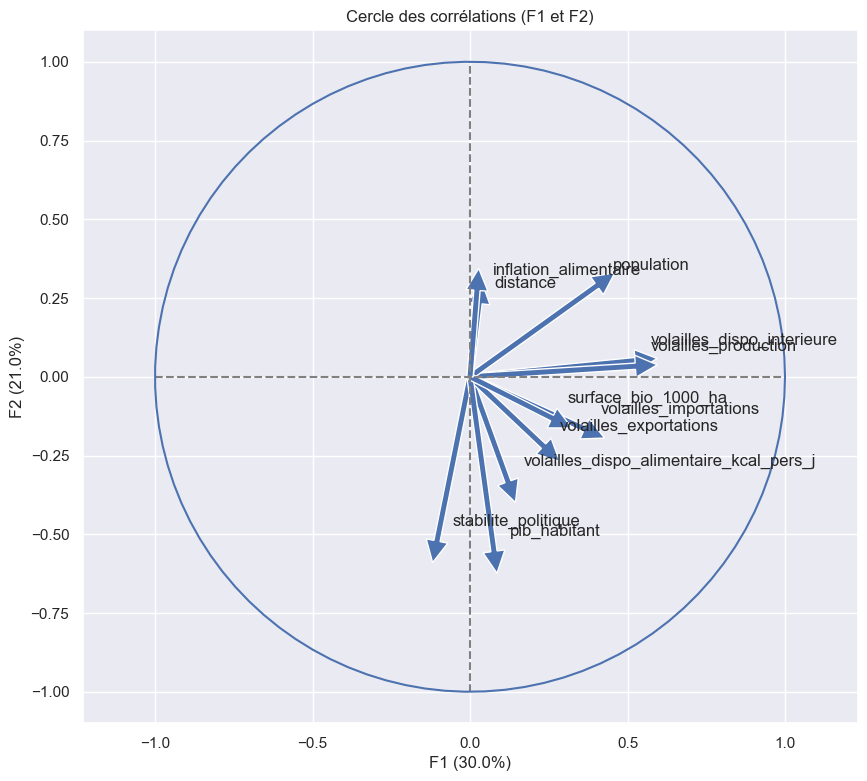

In [40]:
# Plan F1 / F2
correlation_graph(pca, (0, 1), features)

**Interprétation de F1 (30.4%)**


Variables corrélées positivement à F1 (flèches vers la droite) : 
- volailles_dispo_interieure
- volailles_exportations
- volailles_importations
- population


Il ne semble pas y avoir de variables corrélées négativement à F1.


On peut supposer que F1 représente l'activité de la filière volaille d'un pays. Plus un pays est à droite de notre graphique, plus sa filière volaille est développée.


**Interprétation de F2 (18.4%)**


Variables corrélées positivement à F2 (flèches vers le haut) :
- inflation_alimentaire
- population
- distance


Variables corrélées négativement à F2 (flèches vers le bas) :
- stabilite_politique
- pib_habitant


On peut supposer que F2 est lié au niveau de développement économique d'un pays. Les pays en haut du graphique sont plus éloignés, moins stable et connaissent une forte inflation, tandis que les pays en bas du graphique ont tendance à être plus riches et stables politiquement.




**Points d'attention**


surface_bio_1000_ha, distance et inflation_alimentaire ont des flèches très courtes. Elles ne sont pas bien représentées sur ce plan. Mieux vaut éviter de tirer des conclusions en se basant sur ces variables, dans ce plan.


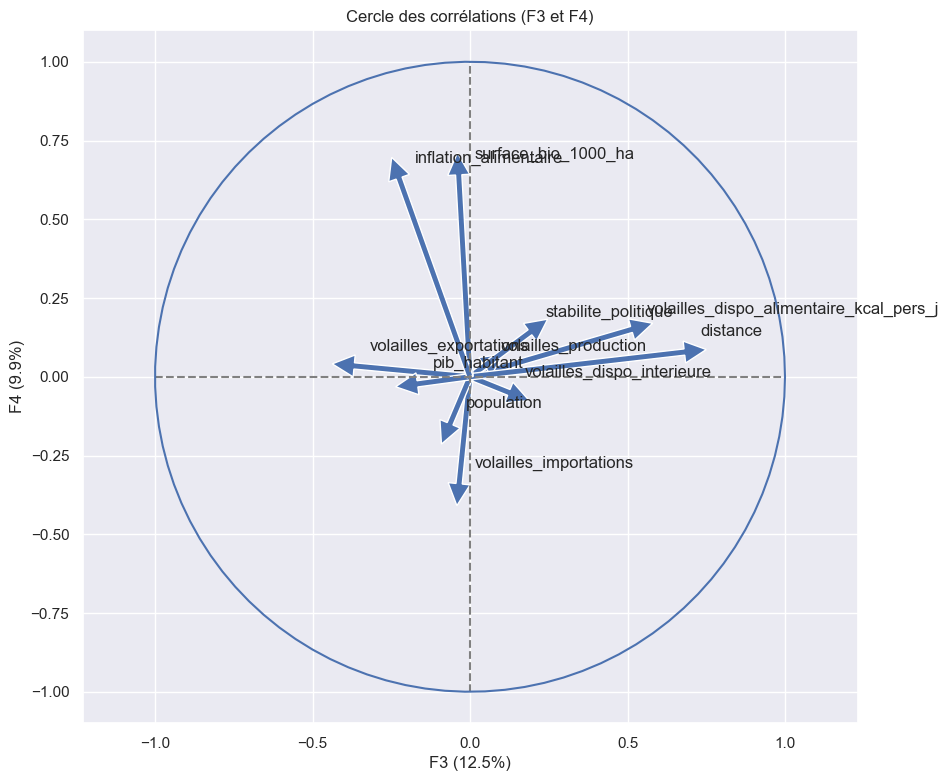

In [41]:
# Plan F3 / F4
correlation_graph(pca, (2, 3), features)

**Interprétation de F3 (13.1%)**

Variables corrélées positivement à F3 (flèches vers la droite):
- distance
- surface_bio_1000_ha
- volailles_dispo_alimentaire_kcal_pers_j

Variables corrélées négativement à F3 (flèches vers la gauche) :
- volailles_importations
- pib_habitant

F3 semble lié à l'éloignement de la France et au développement de la filière bio. Les pays situés à droite du graphique sont loin de la France, ont une grande surface dédiées à l'agriculture biologique, ont une plus importante disponibilité en viande de volaille par personne et ont donc tendance à moins en importer. Le PIB par habitant dans ces pays a aussi tendance a être plus faible. Les pays situés à gauche sont plus proche, importent davantage de volailles, et le PIB par habitant y est plus élevé.


**Interprétation de F4 (9.0%)**

Variables corrélées positivement à F4 (flèches vers le haut) :
- volailles_exportations
- inflation_alimentaire

Variables corrélées négativement à F4 (flèches vers le bas) :
- volailles_importations
- population
- surface_bio_1000_ha

F4 semble centré autour du profil exportateur vs importateur des pays. Les pays en haut du graphique exportent davantage et connaissent une forte inflation. Les pays en bas sont de grands importateurs et ont tendance à être plus peuplés.

**Points d'attention**

Les variables distance et surface_bio_1000_ha qui étaient assez mal représentées sur le plan F1 / F2 sont bien représentées dans le plan F3 / F4. Elles  semblent donc apporter une information indépendante des autres variables.

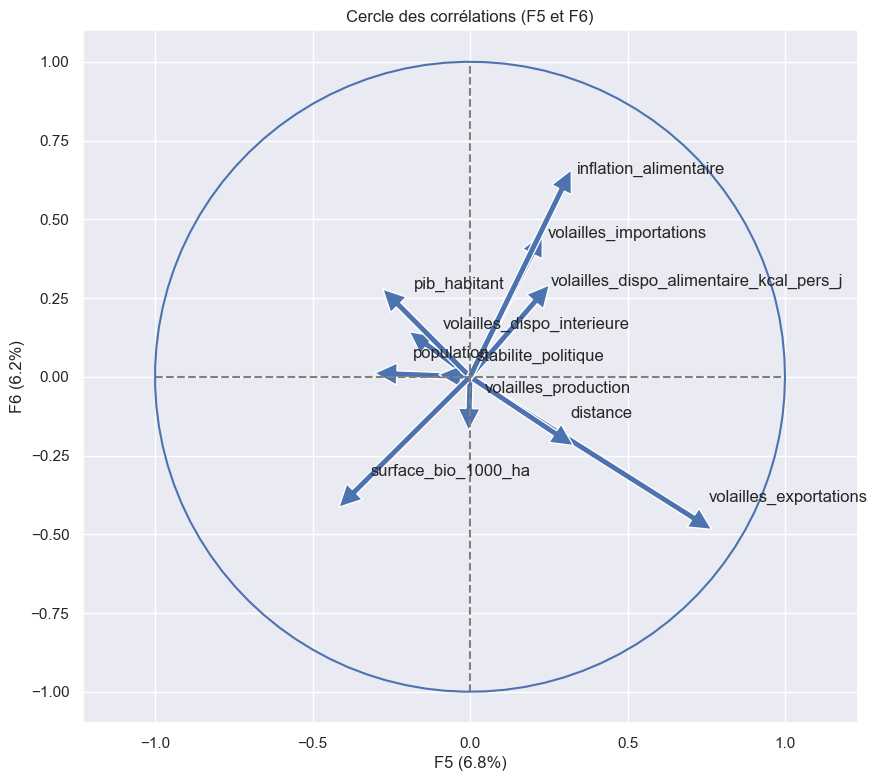

In [42]:
# Plan F5 / F6
correlation_graph(pca, (4, 5), features)

**Interprétation de F5 (8.0%)**


Variables corrélées positivement à F5 (flèches vers la droite):
- inflation_alimentaire
- surface_bio_1000_ha


Variables corrélées négativement à F5 (flèches vers la gauche) :
- distance


On peut supposer que F5 représente l'inflation et le développement de la filière biologique. Les pays situés à droite du graphique connaissent une forte inflation alimentaire mais disposent d'une grande surface dédiée à l'agriculture biologique. Ils sont aussi moins éloignés de la France.


**Interprétation de F6 (7.8%)**


La sixième composante ne remplissait pas le critère de Kaiser. Nous n'allons donc pas nous y intéresser. Nous remarquons néanmoins qu'elle est extrêmement corrélées positivement à l'importation de volaille.


## 4.5 Projection des pays

In [43]:
def display_factorial_planes(   X_projected, 
                                x_y, 
                                pca=None, 
                                labels = None,
                                clusters=None, 
                                alpha=1,
                                figsize=[14,10], 
                                marker="." ):


    X_ = np.array(X_projected)

    if not figsize: 
        figsize = (7,6)

    if  labels is None : 
        labels = []
    try : 
        len(labels)
    except Exception as e : 
        raise e

    if not len(x_y) ==2 : 
        raise AttributeError("2 axes sont demandées")   
    if max(x_y )>= X_.shape[1] : 
        raise AttributeError("la variable axis n'est pas bonne")   

    x, y = x_y

    fig, ax = plt.subplots(1, 1, figsize=figsize)

    c = None if clusters is None else clusters
 
    sns.scatterplot(data=None, x=X_[:, x], y=X_[:, y], hue=c)

    if pca : 
        v1 = str(round(100*pca.explained_variance_ratio_[x]))  + " %"
        v2 = str(round(100*pca.explained_variance_ratio_[y]))  + " %"
    else : 
        v1=v2= ''

    ax.set_xlabel(f'F{x+1} {v1}')
    ax.set_ylabel(f'F{y+1} {v2}')

    x_max = np.abs(X_[:, x]).max() *1.1
    y_max = np.abs(X_[:, y]).max() *1.1

    ax.set_xlim(left=-x_max, right=x_max)
    ax.set_ylim(bottom= -y_max, top=y_max)

    plt.plot([-x_max, x_max], [0, 0], color='grey', alpha=0.5)
    plt.plot([0,0], [-y_max, y_max], color='grey', alpha=0.5)

    if len(labels) : 
        for i,(_x,_y) in enumerate(X_[:,[x,y]]):
            plt.text(_x, _y+0.05, labels[i], fontsize='7', ha='center',va='center') 

    plt.title(f"Projection des individus (sur F{x+1} et F{y+1})")
    plt.show()

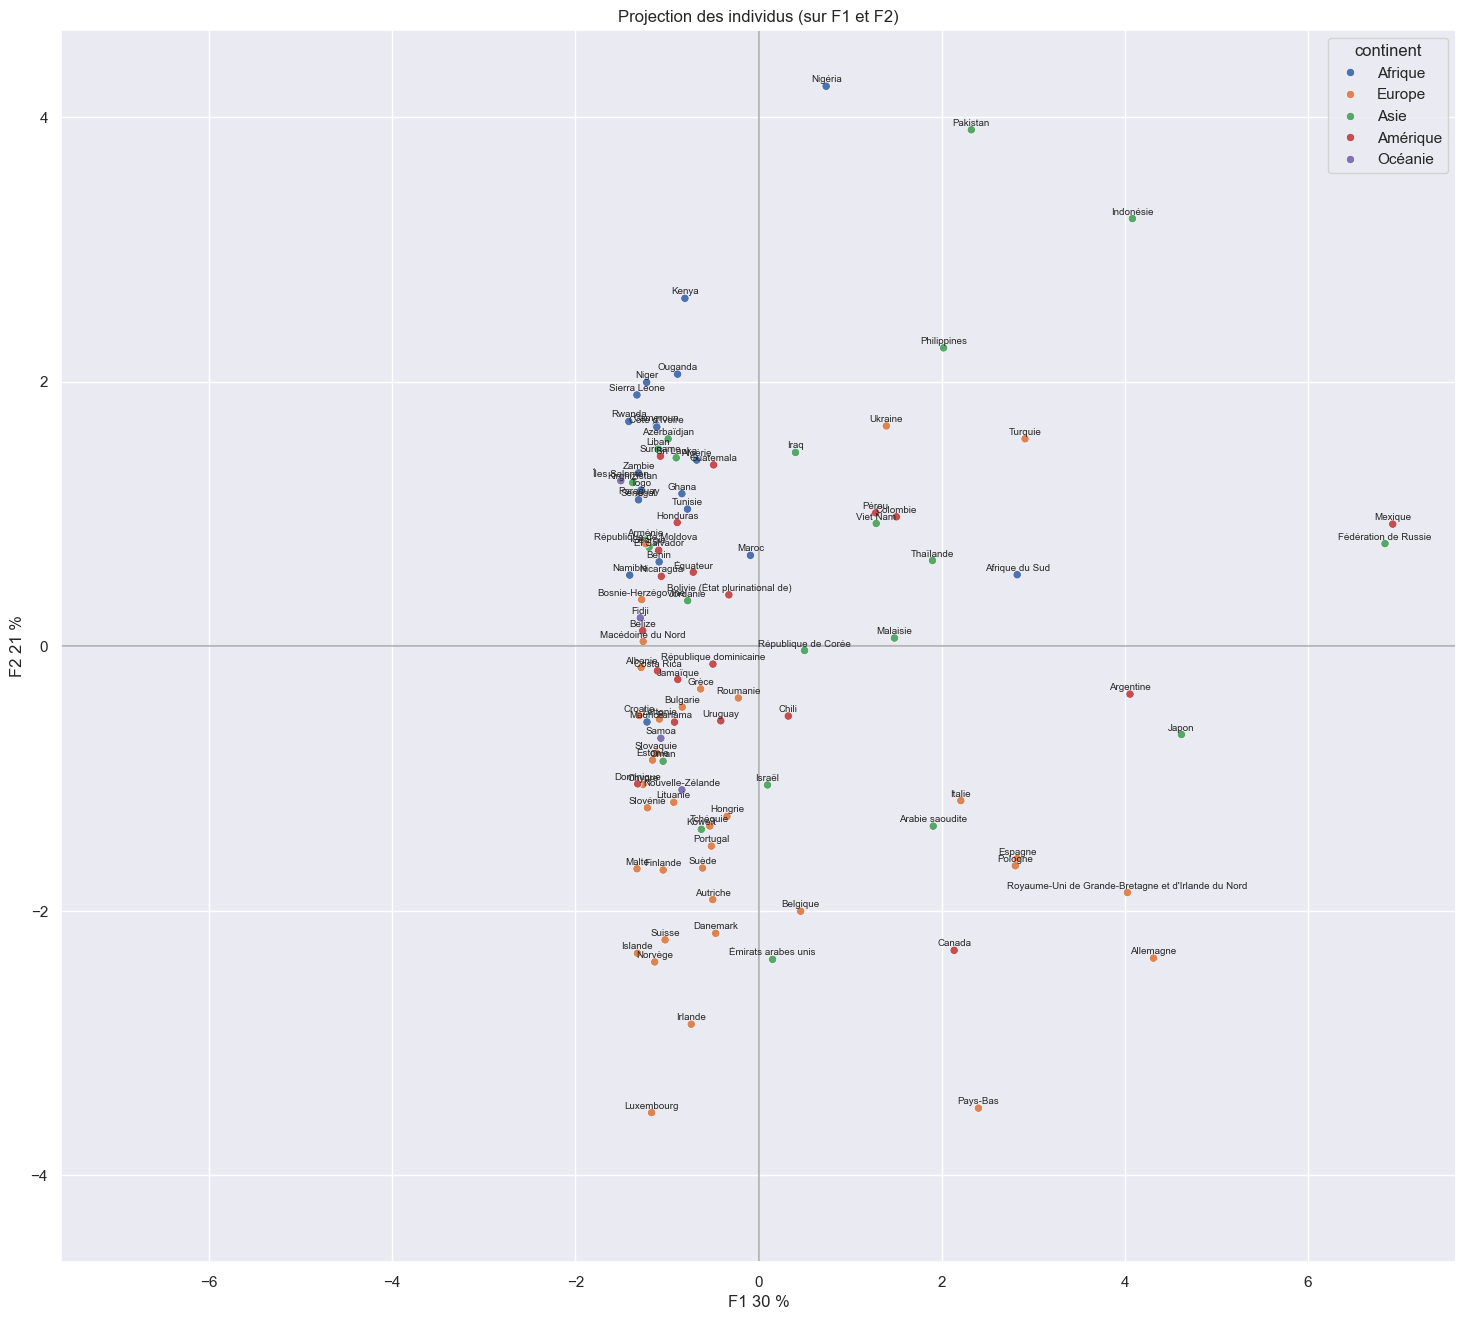

In [44]:
display_factorial_planes(X_proj, 
                         (0, 1), 
                         pca,
                         labels=names,
                         clusters=df['continent'],
                         figsize=(18,16))

**Observations**

On peut déjà dire que le nuage de points est très allongé verticalement (axe F2) et peu étalé horizontalement (axe F1). On note aussi la présence d'outliers à droite.

**Lecture de l'axe F1 (activité de la filière volaille):*Pour rappel, nous avons retiré du jeu de donnéestlest des Etats-s, de la Chinleet du Brésil. Ce sont des pays ayant une filière volaille très développée.
- L'immense majorité des pays se trouvent au centre. Le développement de l'activité lié à la volaille dans ces pays est dans la norme.
- On ne trouve pas à gauche des outliers comme on en trouve à droite. Certains pays sont néanmoins un peu plus en marge que les autres, comme le Nigeria, le Sierra Leone ou le Kenya.

**Lecture de l'axe F2 (développement économique inversé):**
- On trouve en haut des pays en développement économique avec une inflation élevée et instables politnt (Inde, Nigeria, Pakistan)
- En bas se trouvent plutôt des pays riches, stables politiquement, avec une faible inflation , Australie)

**Conclusion:**
Dans le cadre de notre étude, et en se basant sur ce plan, ce sont les pays situés au centre bas ou à la rigueur au centre gauche qui devraient être les plus susceptibles de nous intéresser. Soit des pays riches, stables avec un pouvoir d'achat élevé, n'ayant pas une filière de la viande de volaille trop développée (mais pas trop peu développée non plus, ce qui pourrait être la conséquence d'un manque d'intérêt de la population pour cettelimentation).


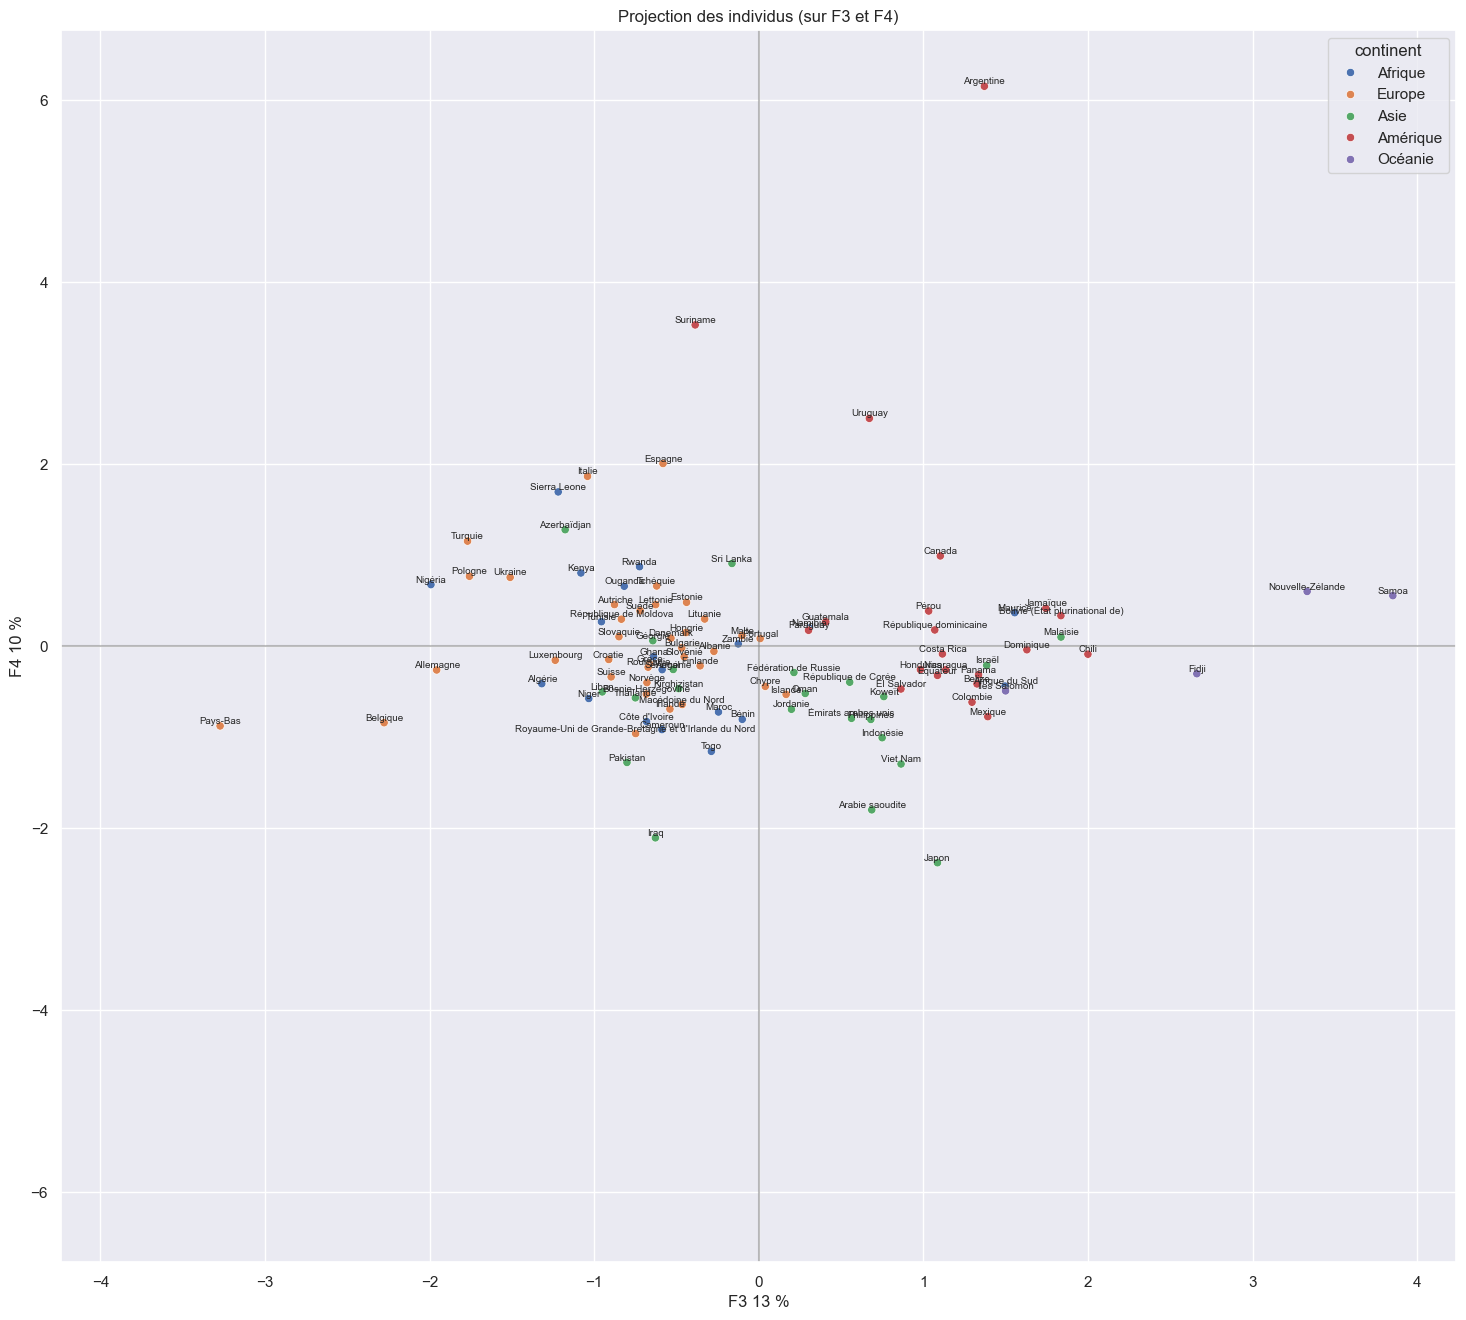

In [45]:
display_factorial_planes(X_proj, 
                         (2, 3), 
                         pca,
                         labels=names,
                         clusters=df['continent'],
                         figsize=(18,16))

**Observations**

Le nuage de points est cette fois bien plus centré que dans le plan précédent, que l'on regarde l'axe horizontal ou l'axe vertical. On peut néanmoins voir quelques outliers, principalement sur l'axe vertical.

**Lecture de l'axe F3 (éloignement et développement de la filière bio):**
- Les pays situés à droite de ce graphique sont très éloignés de la France et ont une agriculture bio développée.
- La très grande majorité des pays se trouvent au centre, avec une distance de la France moyenne et une surface dédiée à l'agriculture biologique moyenne.
- Les pays situés à gauche du graphique sont proches de la France, et semblent avoir développé peu de surface dédiée à l'agriculture biologique. On y trouve le Royaume-Uni, l'Allemagne, les Pays-Bas ou le Luxembourg.

**Lecture de l'axe F4 (profil exportateur / importateur des pays):**
- On trouve en haut du graphique les grands pays exportateurs de(volailleats-Unis, Suriname,).rgentine).
- Au centre les pays avec un équilibre import/export de ce produit.
- Les grands importateurs ou consommateurs dont en bas (Japon, Mexique, Allemagne) Allemagne).

**Conclusion:**
Dans le cadre de notre étude, et en se basant sur ce plan, ce sont les pays situés en bas et à gauche qui devraient être les plus susceptibles de nous intéresser. Ceux situés en bas au centre présentent aussi un intérêt (importateur et sensibles à l'agriculture biologique). Ces pays sont de grands importateurs de volailles, et se situent près de la France. À l'inverse, les pays situés en haut du graphique sont nos concurrents.


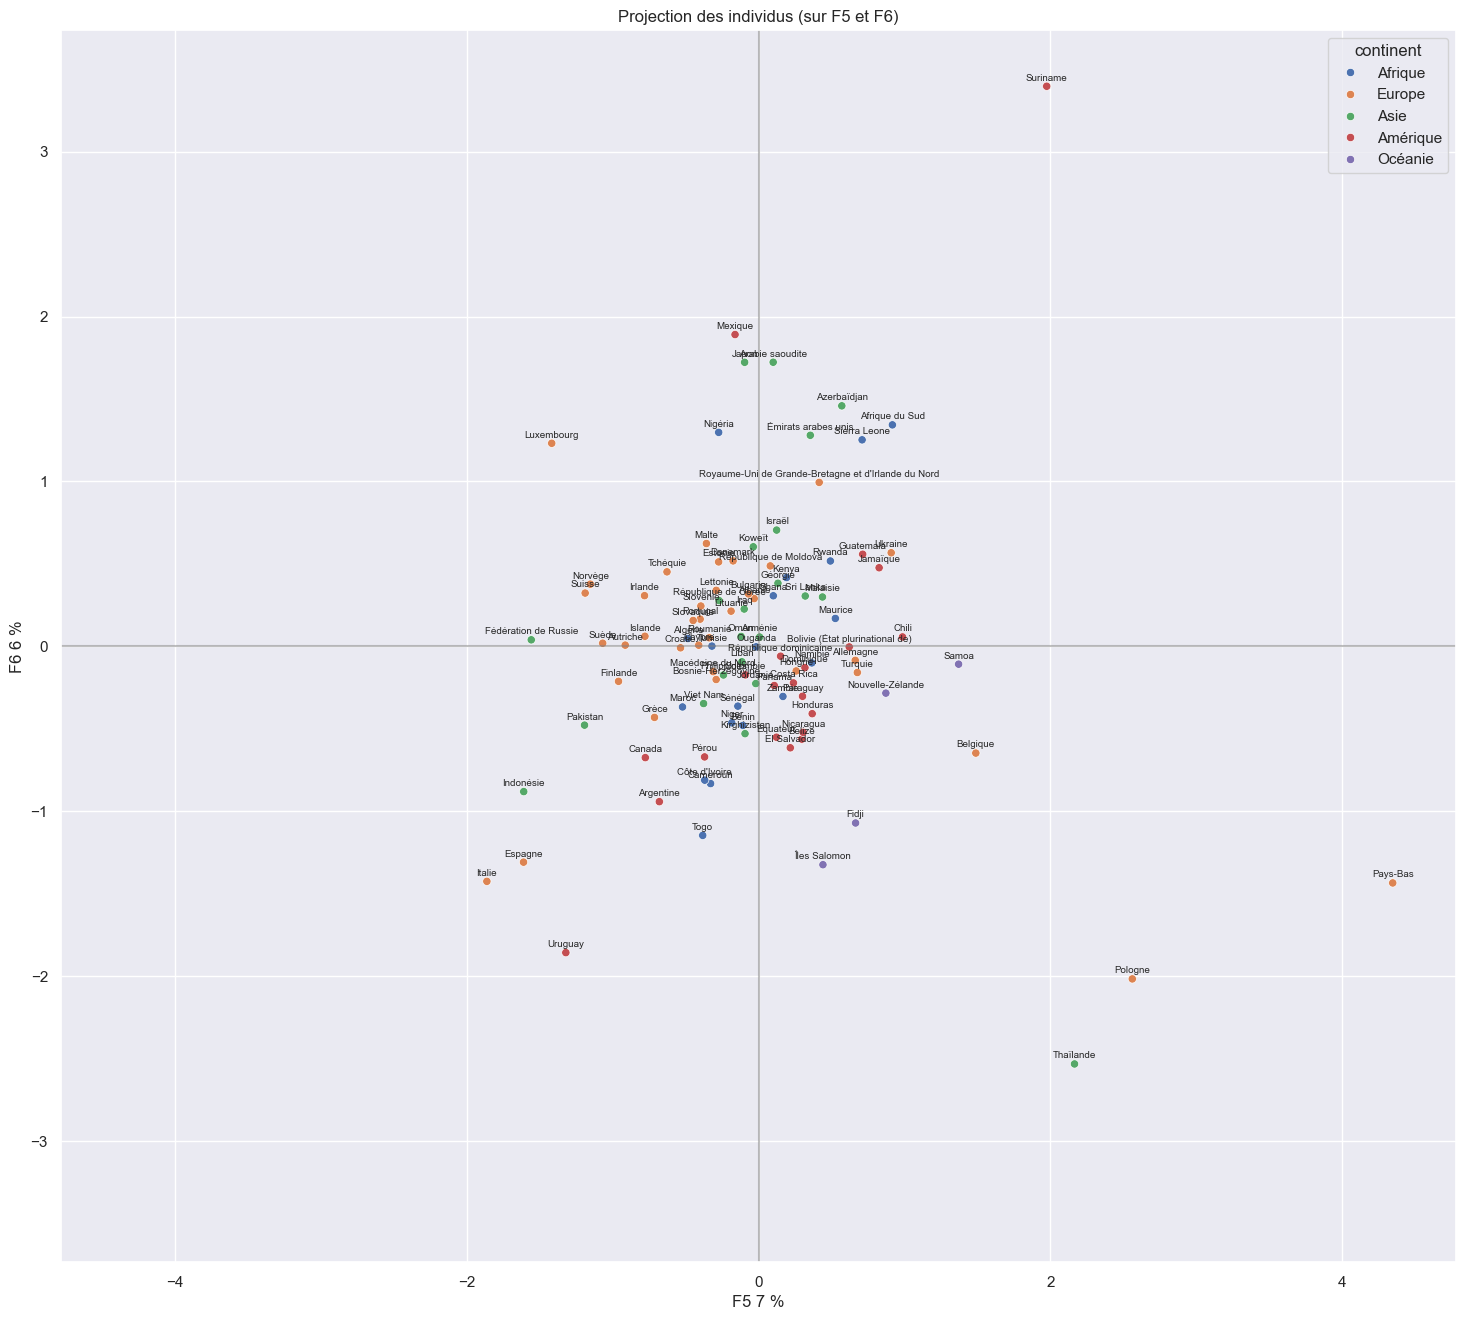

In [46]:
display_factorial_planes(X_proj, 
                         (4, 5), 
                         pca,
                         labels=names,
                         clusters=df['continent'],
                         figsize=(18,16))

**Observations**

Là encore, le nuage de points est plutôt centré bien qu'un peu étalé sur l'axe des ordonnées. On voit aussi quelques outliers sur la droite du graphique.

**Lecture de l'axe F5 (inflation et développement de la filière biologique):**
- Les pays situés à droite de ce graphique ont connu une forte inflation alimentaire en 2017, et avaient grande surface dédiée à l'agriculture biologique (Suriname, Argentine)
- La grande majorité des pays se trouvent là aussi au centre. Ils présentent donc un profil "moyen" regardant cette composante.
- Les pays situés à gauche du graphique ont connu une faible inflation, et présentent peu de surface bio.

**Lecture de l'axe F6 (importation de volaille):**

Nous n'allons pas nous intéresser de trop près à la lecture de cet axe. Les pays situés en haut de ce graphique sont néanmoins de grands importateurs de volailles (Mexique, Japon, Arabie saoudite, Afrique du Sud, Royaume-Uni, Allemagne)

**Conclusion et synthèse:**

La lecture et l'analyse de nos cercles des corrélations et de la projections des individus nous permet de nous faire une meilleure idée du profil idéal de nos pays à cibler. Il s'agit de pays n'ayant pas une industrie de la filière volaille trop ou trop peu développée (F1 centre), riche et stable (F2 bas), proche de la France (F3 gauche), grand importateur de volaille (F4 bas et F6 haut), et sensible à l'agriculture biologique (F3/F5 élevé).

Des pays correspondant à ce profil seraient l'Allemagne, les Pays-Bas, le Royaume-Uni ou la Belgique en Europe, l'Arabie saoudite ou les Émirats arabes unis au Moyen-Orient (le Japon aurait aussi un profil idéal, mais il est probablement situé un peu troip ln).


# 5 - Clustering

## 5.1 Classification ascendante hiérarchique (ou CAH)

Commençons par calculer les distances avec la méthode de Ward

In [47]:
Z = linkage(X_scaled, method="ward")

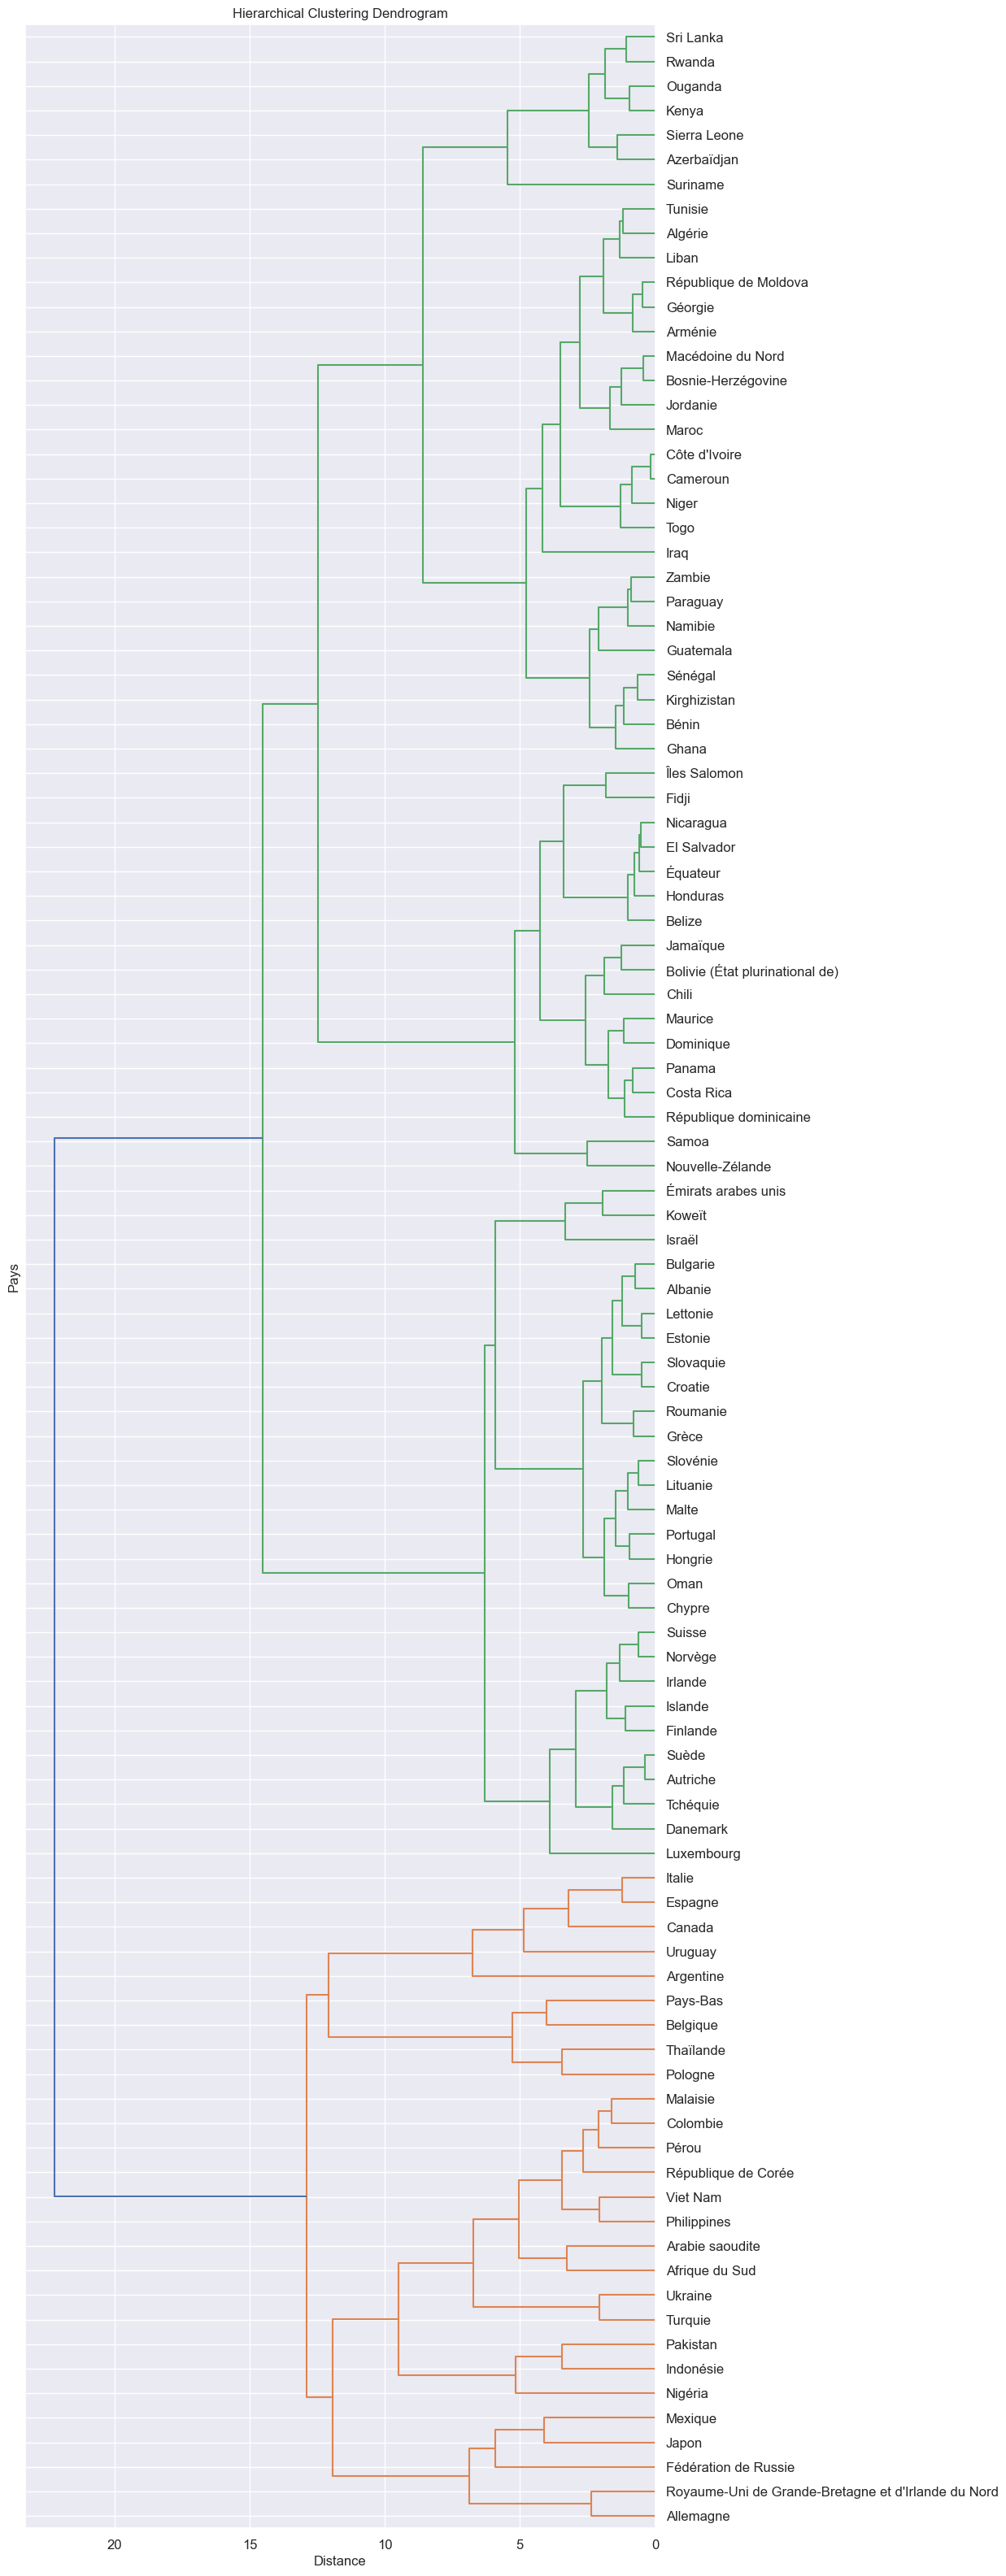

In [48]:
fig, ax = plt.subplots(1, 1, figsize=(10,40))

full_den = dendrogram(Z, ax=ax, labels=names, orientation = "left")

plt.title("Hierarchical Clustering Dendrogram")
ax.set_xlabel("Distance")
ax.set_ylabel("Pays")
ax.tick_params(axis='x', which='major', labelsize=12)
ax.tick_params(axis='y', which='major', labelsize=12)

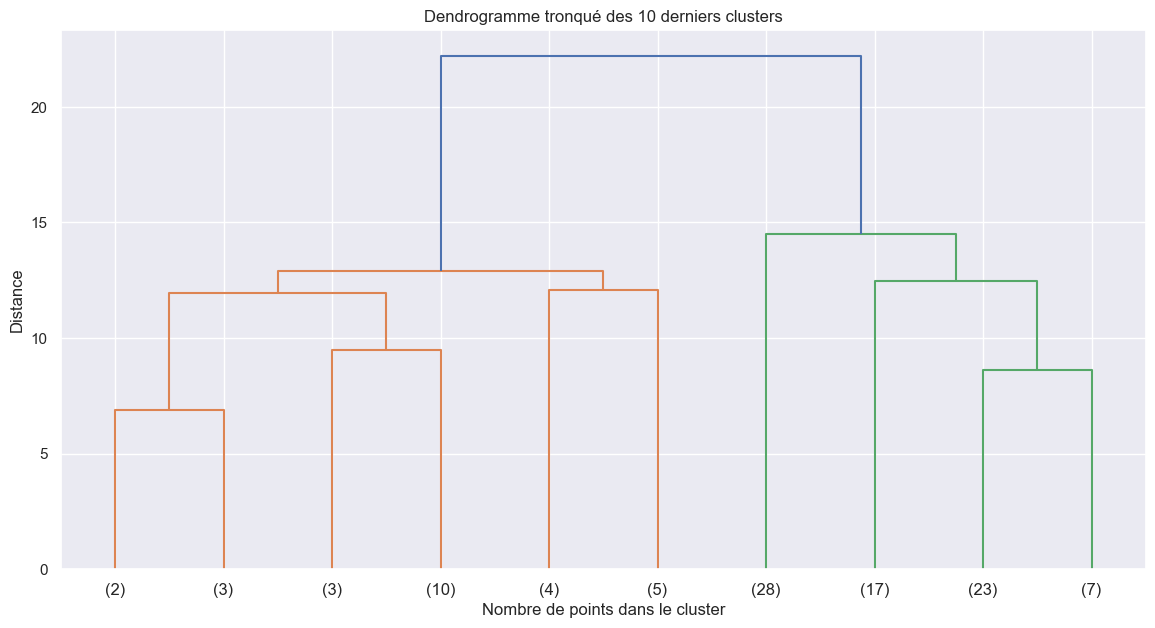

In [49]:
fig, ax = plt.subplots(1, 1, figsize=(14, 7))
dendrogram(Z, ax=ax, p=10, truncate_mode='lastp')
ax.set_title('Dendrogramme tronqué des 10 derniers clusters')
ax.set_xlabel('Nombre de points dans le cluster')
ax.set_ylabel('Distance')

plt.show()

In [50]:
k_cah = 5

labels_cah = fcluster(Z, k_cah, criterion='maxclust')

In [51]:
labels_cah

array([1, 3, 5, 1, 1, 2, 5, 3, 5, 2, 4, 4, 5, 3, 5, 5, 2, 4, 3, 1, 4, 3,
       5, 3, 4, 4, 2, 3, 4, 3, 1, 5, 3, 5, 5, 4, 3, 1, 5, 3, 3, 3, 2, 4,
       1, 5, 5, 5, 3, 3, 5, 3, 3, 5, 1, 3, 5, 4, 1, 5, 4, 5, 1, 3, 4, 3,
       5, 1, 4, 5, 2, 1, 2, 3, 1, 3, 1, 5, 1, 5, 4, 4, 5, 3, 3, 5, 3, 5,
       3, 5, 3, 2, 5, 5, 1, 1, 2, 1, 5, 3, 4, 4], dtype=int32)

In [52]:
print(f'Répartition des éléments dans les 5 clusters (CAH) :')
print(pd.Series(labels_cah).value_counts().sort_index())

Répartition des éléments dans les 5 clusters (CAH) :
1    18
2     9
3    28
4    17
5    30
Name: count, dtype: int64


Affichons la liste des pays par cluster:

In [53]:
df_copy = df.copy()
df_copy['cluster_cah'] = labels_cah

In [54]:
print("Cluster 1:\n")

df_copy[df_copy['cluster_cah'] == 1][['pays', 'continent']].sort_values('continent')

Cluster 1:



,pays,continent
0,Afrique du Sud,Afrique
62,Nigéria,Afrique
74,Pérou,Amérique
58,Mexique,Amérique
19,Colombie,Amérique
30,Fédération de Russie,Asie
37,Indonésie,Asie
44,Japon,Asie
54,Malaisie,Asie
4,Arabie saoudite,Asie


In [55]:
print("Cluster 2:\n")

df_copy[df_copy['cluster_cah'] == 2][['pays', 'continent']].sort_values('continent')

Cluster 2:



,pays,continent
5,Argentine,Amérique
16,Canada,Amérique
96,Uruguay,Amérique
91,Thaïlande,Asie
9,Belgique,Europe
26,Espagne,Europe
42,Italie,Europe
70,Pays-Bas,Europe
72,Pologne,Europe


In [56]:
print("Cluster 3:\n")

df_copy[df_copy['cluster_cah'] == 3][['pays', 'continent']].sort_values('continent').head(50)

Cluster 3:



,pays,continent
48,Koweït,Asie
65,Oman,Asie
41,Israël,Asie
99,Émirats arabes unis,Asie
21,Croatie,Europe
88,Suède,Europe
86,Suisse,Europe
84,Slovénie,Europe
83,Slovaquie,Europe
75,Roumanie,Europe


In [57]:
print("Cluster 4:\n")

df_copy[df_copy['cluster_cah'] == 4][['pays', 'continent']].sort_values('continent')

Cluster 4:



,pays,continent
57,Maurice,Afrique
10,Belize,Amérique
80,République dominicaine,Amérique
68,Panama,Amérique
60,Nicaragua,Amérique
100,Équateur,Amérique
35,Honduras,Amérique
43,Jamaïque,Amérique
25,El Salvador,Amérique
24,Dominique,Amérique


In [58]:
print("Cluster 5:\n")

df_copy[df_copy['cluster_cah'] == 5][['pays', 'continent']].sort_values('continent')

Cluster 5:



,pays,continent
2,Algérie,Afrique
92,Togo,Afrique
89,Sénégal,Afrique
82,Sierra Leone,Afrique
77,Rwanda,Afrique
66,Ouganda,Afrique
61,Niger,Afrique
59,Namibie,Afrique
56,Maroc,Afrique
93,Tunisie,Afrique


Et visualison la classification ascendante hiérarchique sur le premier plan factoriel

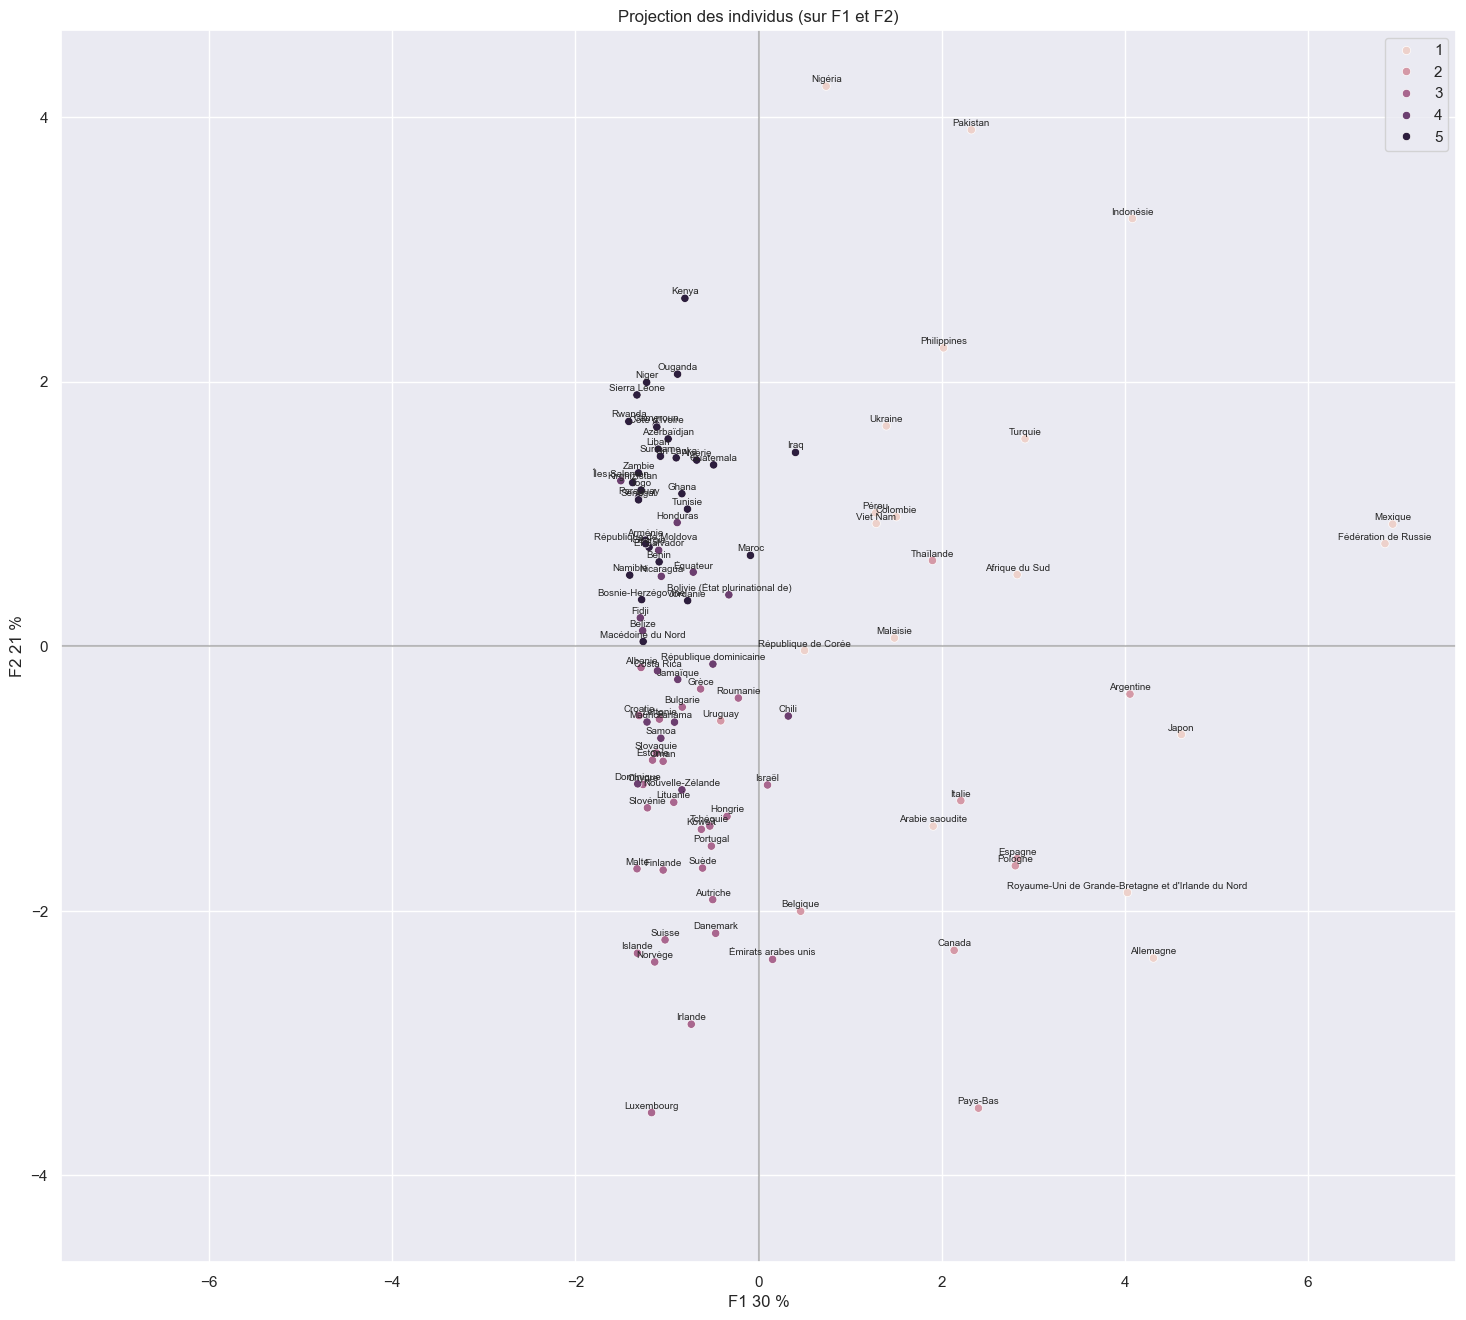

In [59]:
display_factorial_planes(X_proj, 
                        (0, 1), 
                        pca,
                        labels=names,
                        clusters=labels_cah,
                        figsize=(18,16))

Créons un graphique par groupe pour plus de lisibilité.

Cluster 1:

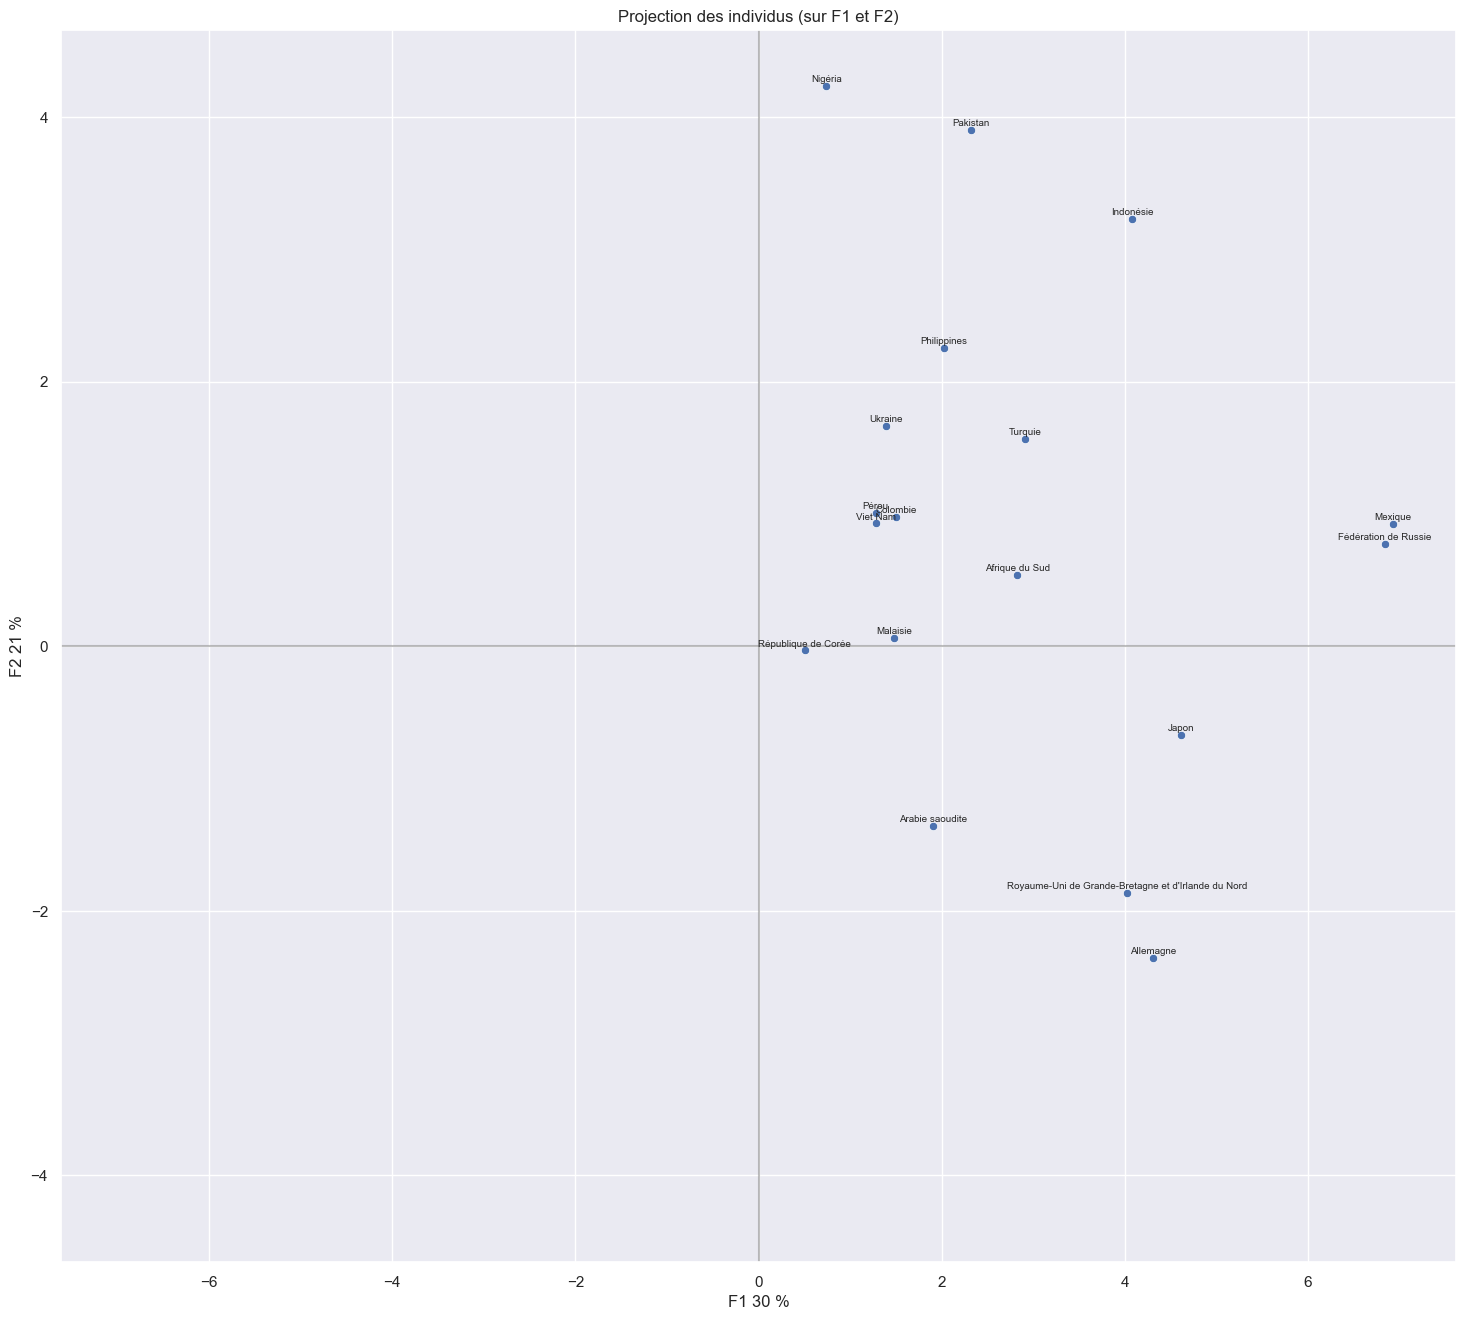

In [60]:
display_factorial_planes(X_proj[labels_cah == 1], 
                        (0, 1), 
                        pca,
                        labels=names[labels_cah == 1],
                        figsize=(18,16))

Cluster 2:

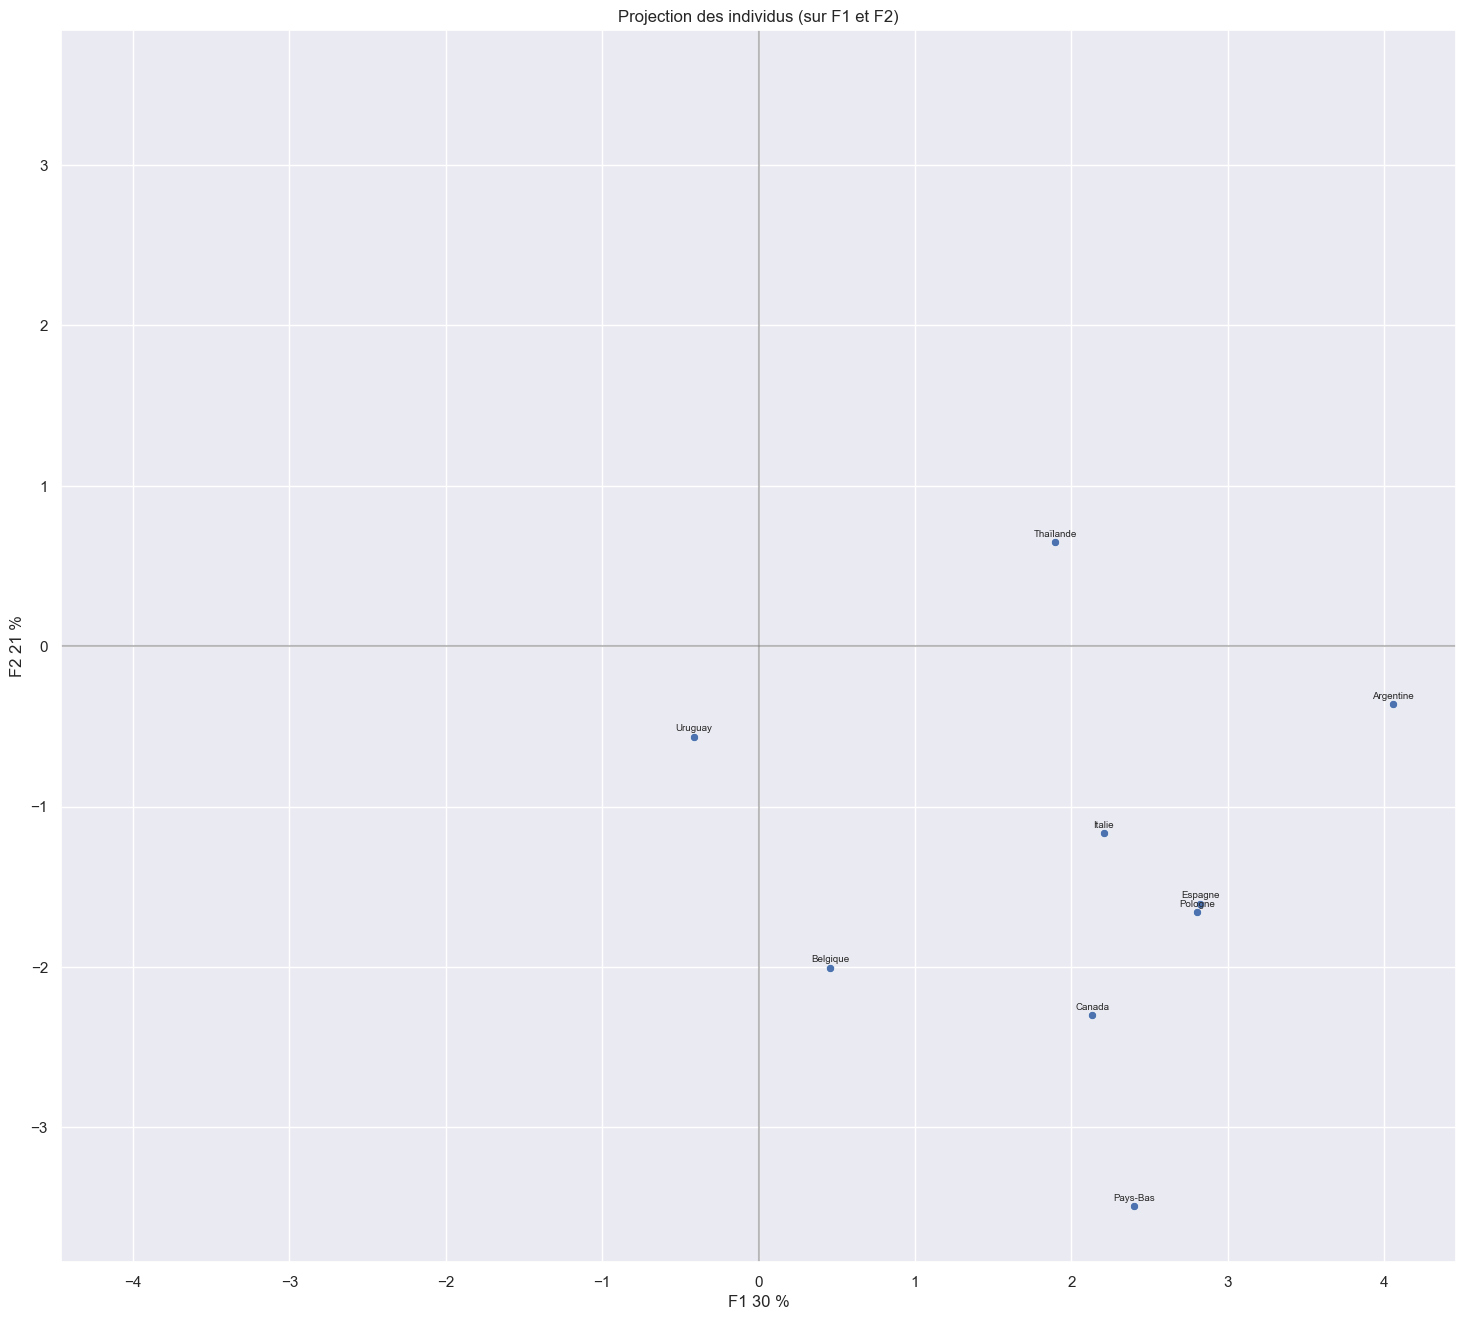

In [61]:
display_factorial_planes(X_proj[labels_cah == 2], 
                        (0, 1), 
                        pca,
                        labels=names[labels_cah == 2],
                        figsize=(18,16))

Cluster 3:

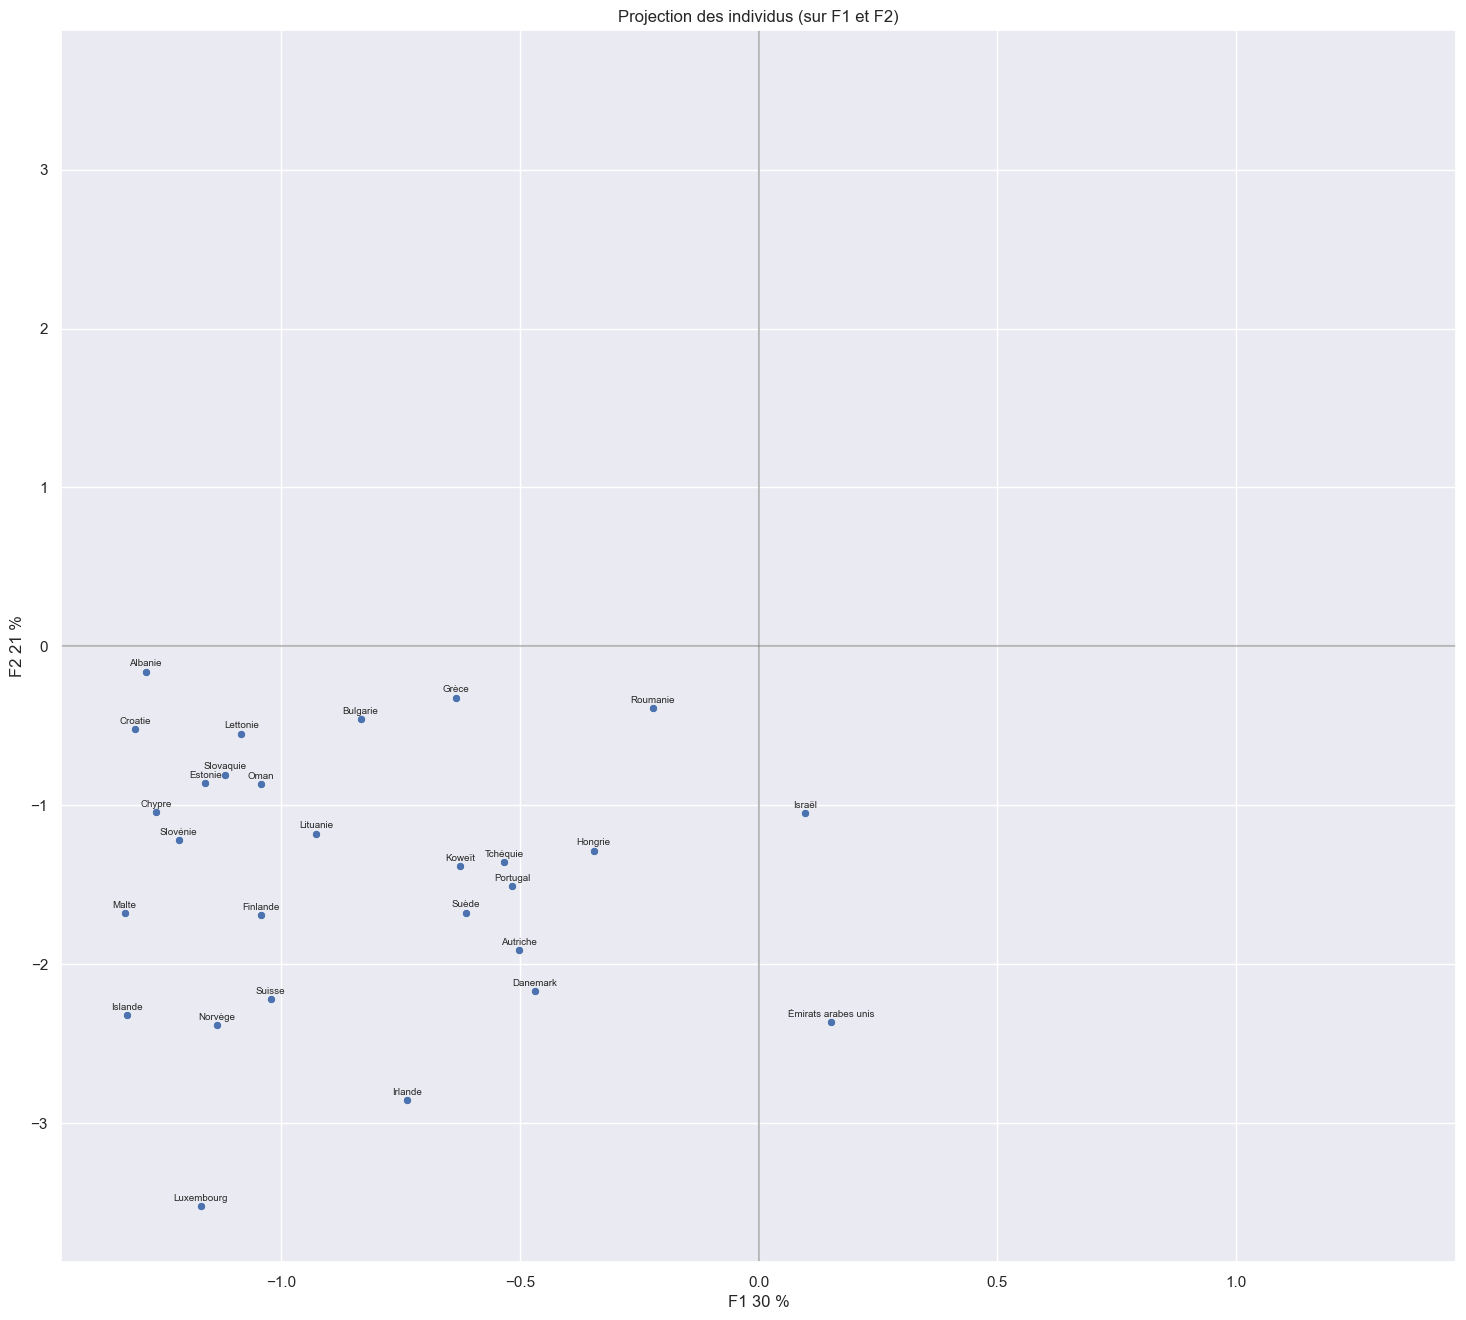

In [62]:
display_factorial_planes(X_proj[labels_cah == 3], 
                        (0, 1), 
                        pca,
                        labels=names[labels_cah == 3],
                        figsize=(18,16))

Cluster 4:

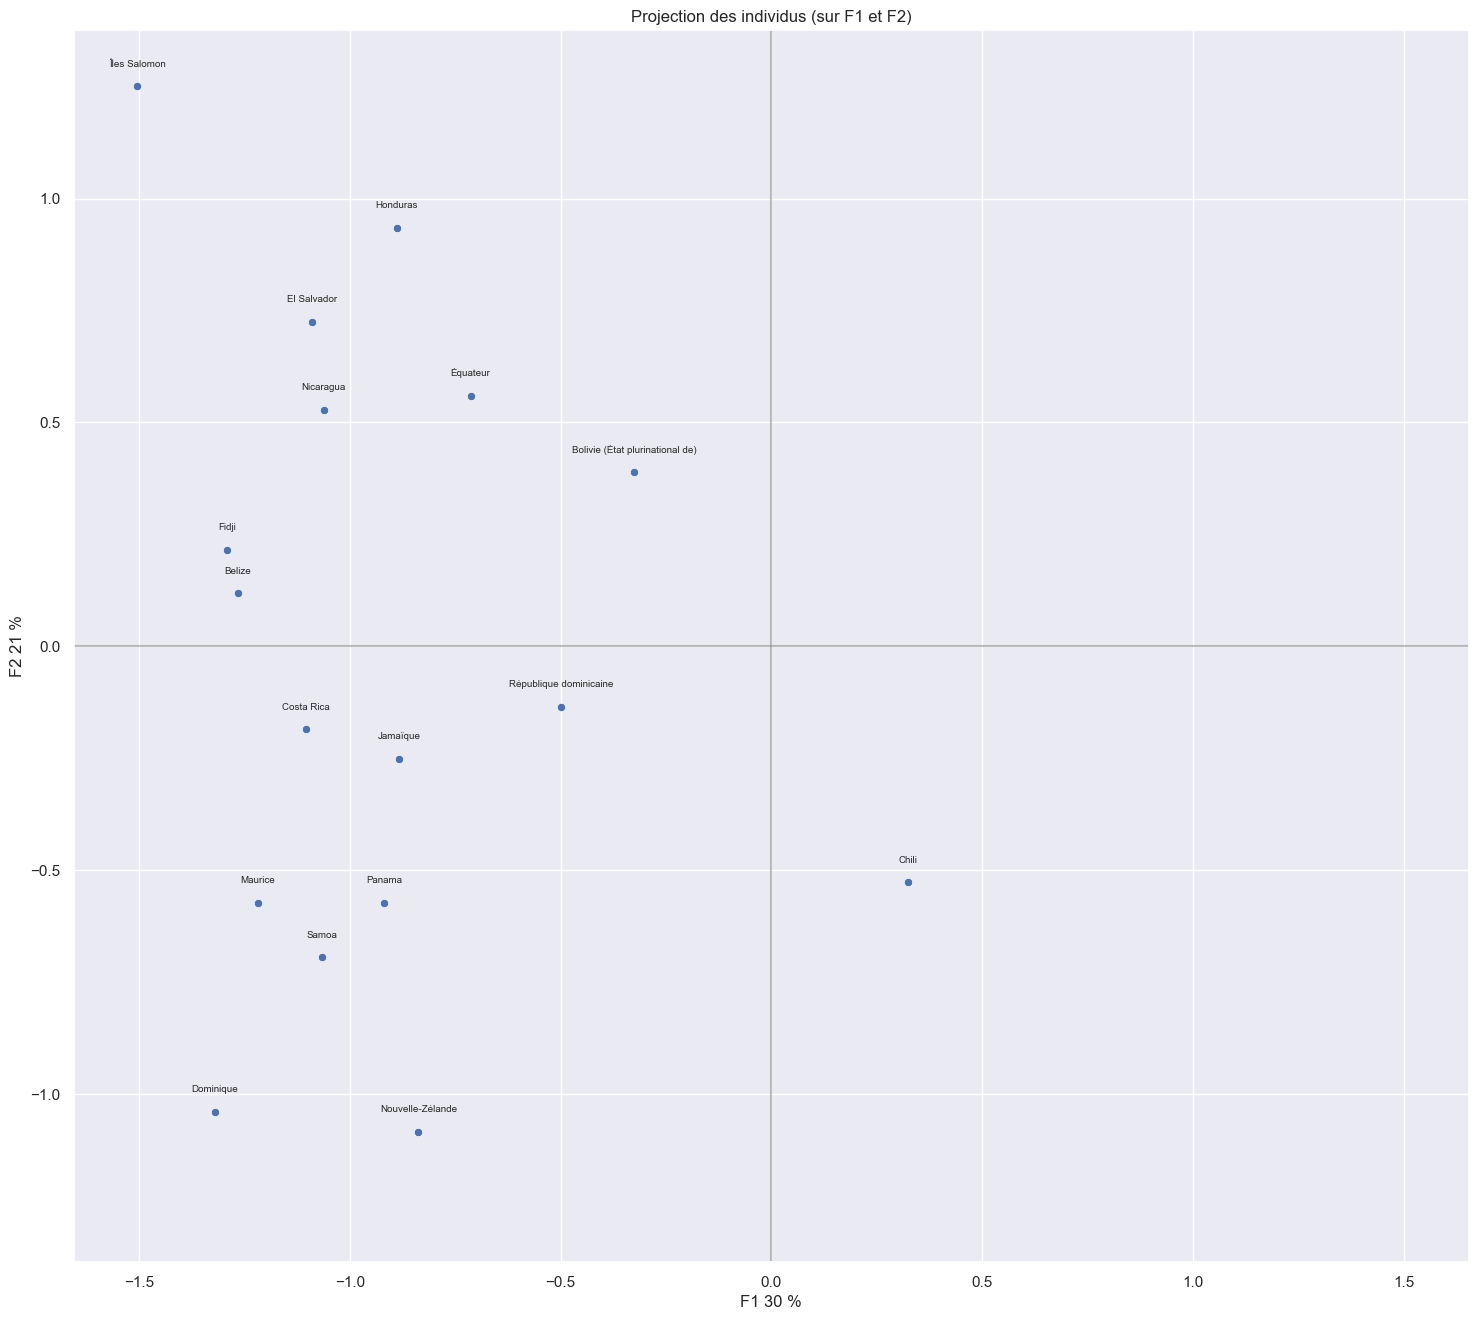

In [63]:
display_factorial_planes(X_proj[labels_cah == 4], 
                        (0, 1), 
                        pca,
                        labels=names[labels_cah == 4],
                        figsize=(18,16))

Cluster 5:

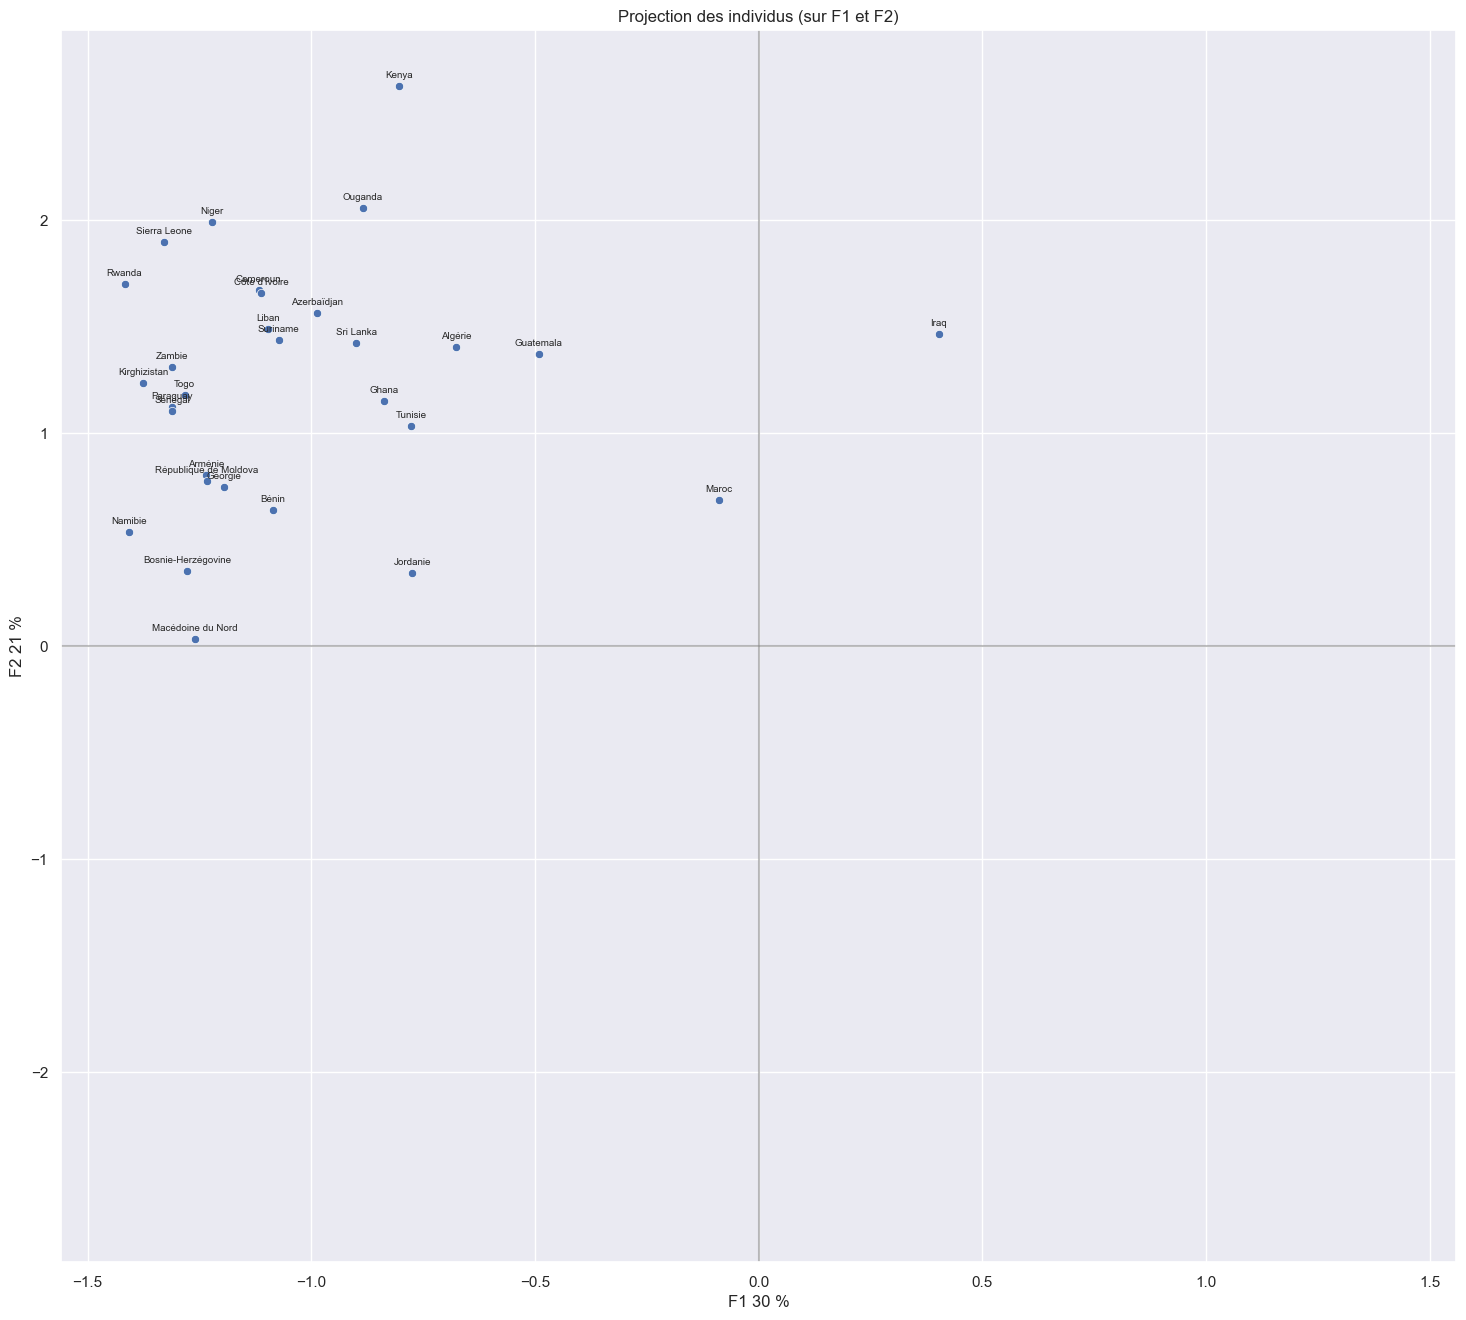

In [64]:
display_factorial_planes(X_proj[labels_cah == 5], 
                        (0, 1), 
                        pca,
                        labels=names[labels_cah == 5],
                        figsize=(18,16))

## 5.2 K-means

### 5.2.1 Méthode du coude

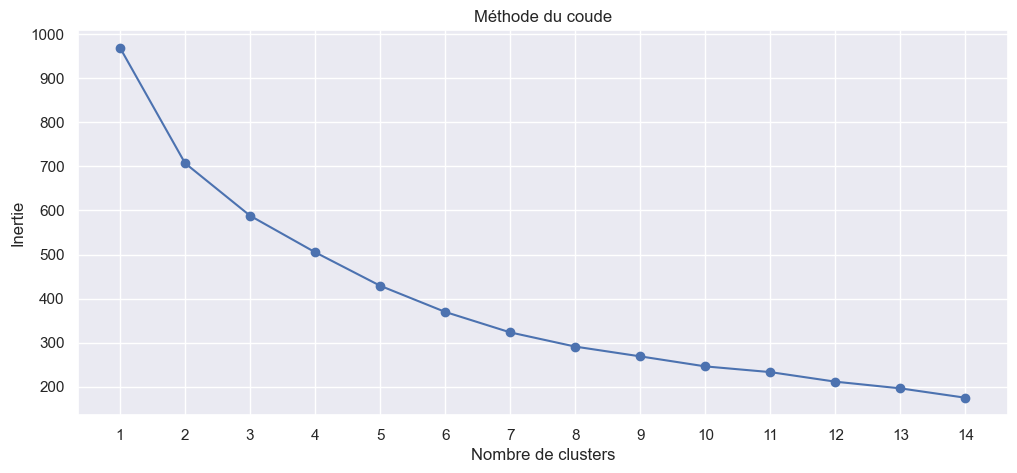

In [66]:
inertia_list = []

k_list = range(1, 15)

for k in k_list:

    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)

    kmeans.fit(X_proj)

    inertia_list.append(kmeans.inertia_)

fig, ax = plt.subplots(1, 1, figsize=(12, 5))

plt.plot(k_list, inertia_list, 'bo-')

plt.xticks(k_list)

plt.xlabel('Nombre de clusters')
plt.ylabel('Inertie')
plt.title('Méthode du coude')

plt.show()

On peut observer une cassure dans la courbe autour de 5-6 clusters. Cette observation semble alignée avec celle effectuée sur le dendrogramme. Nous allons donc conserver une valeur de 5 pour K, le nombre de clusters.

### 5.2.2 K-means final

In [68]:
k_km_final = 5

kmeans = KMeans(n_clusters=k_km_final, n_init=10, random_state=42)

kmeans.fit(X_proj)

labels_km = kmeans.labels_
labels_km

array([4, 1, 3, 2, 4, 2, 3, 1, 3, 1, 0, 0, 3, 1, 3, 3, 2, 0, 1, 4, 0, 1,
       3, 1, 0, 0, 2, 1, 0, 1, 4, 3, 1, 3, 3, 0, 1, 4, 3, 1, 1, 0, 2, 0,
       4, 3, 3, 3, 1, 1, 3, 1, 1, 3, 0, 1, 3, 0, 4, 3, 0, 3, 3, 1, 0, 1,
       3, 4, 0, 3, 2, 4, 2, 1, 0, 1, 2, 3, 0, 3, 0, 0, 3, 1, 1, 3, 1, 3,
       1, 3, 1, 2, 3, 3, 2, 3, 0, 4, 3, 1, 0, 0])

In [69]:
print('Répartition des 5 clusters (K-means):')
print(pd.Series(labels_km).value_counts().sort_index())

Répartition des 5 clusters (K-means):
0    22
1    28
2    10
3    32
4    10
Name: count, dtype: int64


In [70]:
centroids = kmeans.cluster_centers_
centroids

array([[-0.57822272, -0.04172249,  1.56833137,  0.08225797,  0.31961202,
        -0.30250057],
       [-0.81513233, -1.45513534, -0.46938369, -0.10488399, -0.4137668 ,
         0.23924563],
       [ 2.95675014, -1.2584631 , -0.94024014,  1.02807385,  0.58980801,
        -0.95914204],
       [-0.88566707,  1.33550033, -0.61320511,  0.04737838,  0.09279567,
         0.15267243],
       [ 3.431845  ,  1.15103049,  0.7664418 , -1.06697701, -0.43135355,
         0.46620375]])

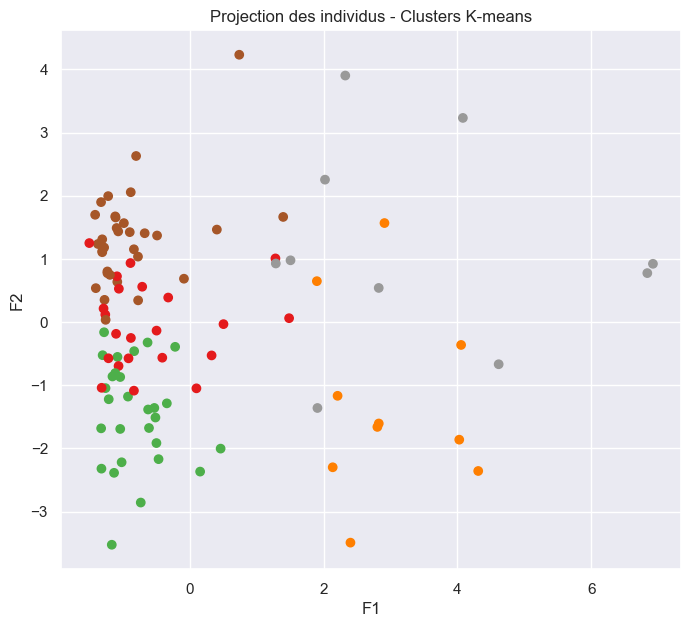

In [71]:
fig, ax = plt.subplots(1, 1, figsize=(8, 7))

ax.scatter(X_proj[:, 0], X_proj[:, 1], c=labels_km, cmap="Set1")

ax.set_xlabel(f"F1")
ax.set_ylabel(f"F2")
ax.set_title("Projection des individus - Clusters K-means")

plt.show()

Visualisons les K-means sur le premier plan factoriel:

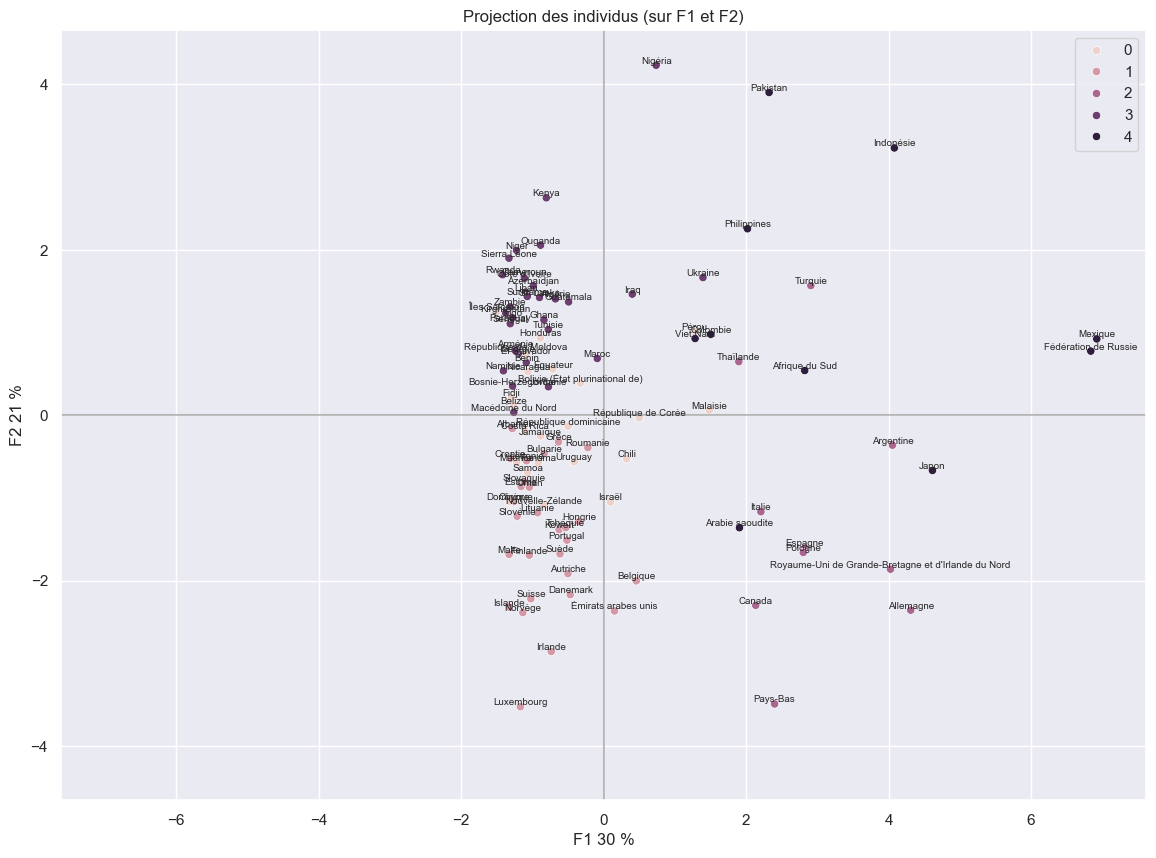

In [72]:
display_factorial_planes(X_proj, 
                         (0, 1), 
                         pca,
                         labels=names,
                         clusters=labels_km)

Regardons à présent chaque cluster plus en détail

In [73]:
df_copy['cluster_km'] = labels_km

In [74]:
print("Cluster 0:\n")

df_copy[df_copy['cluster_km'] == 0][['pays', 'continent']].sort_values('continent').head(50)

Cluster 0:



,pays,continent
57,Maurice,Afrique
10,Belize,Amérique
11,Bolivie (État plurinational de),Amérique
17,Chili,Amérique
20,Costa Rica,Amérique
24,Dominique,Amérique
25,El Salvador,Amérique
96,Uruguay,Amérique
35,Honduras,Amérique
80,République dominicaine,Amérique


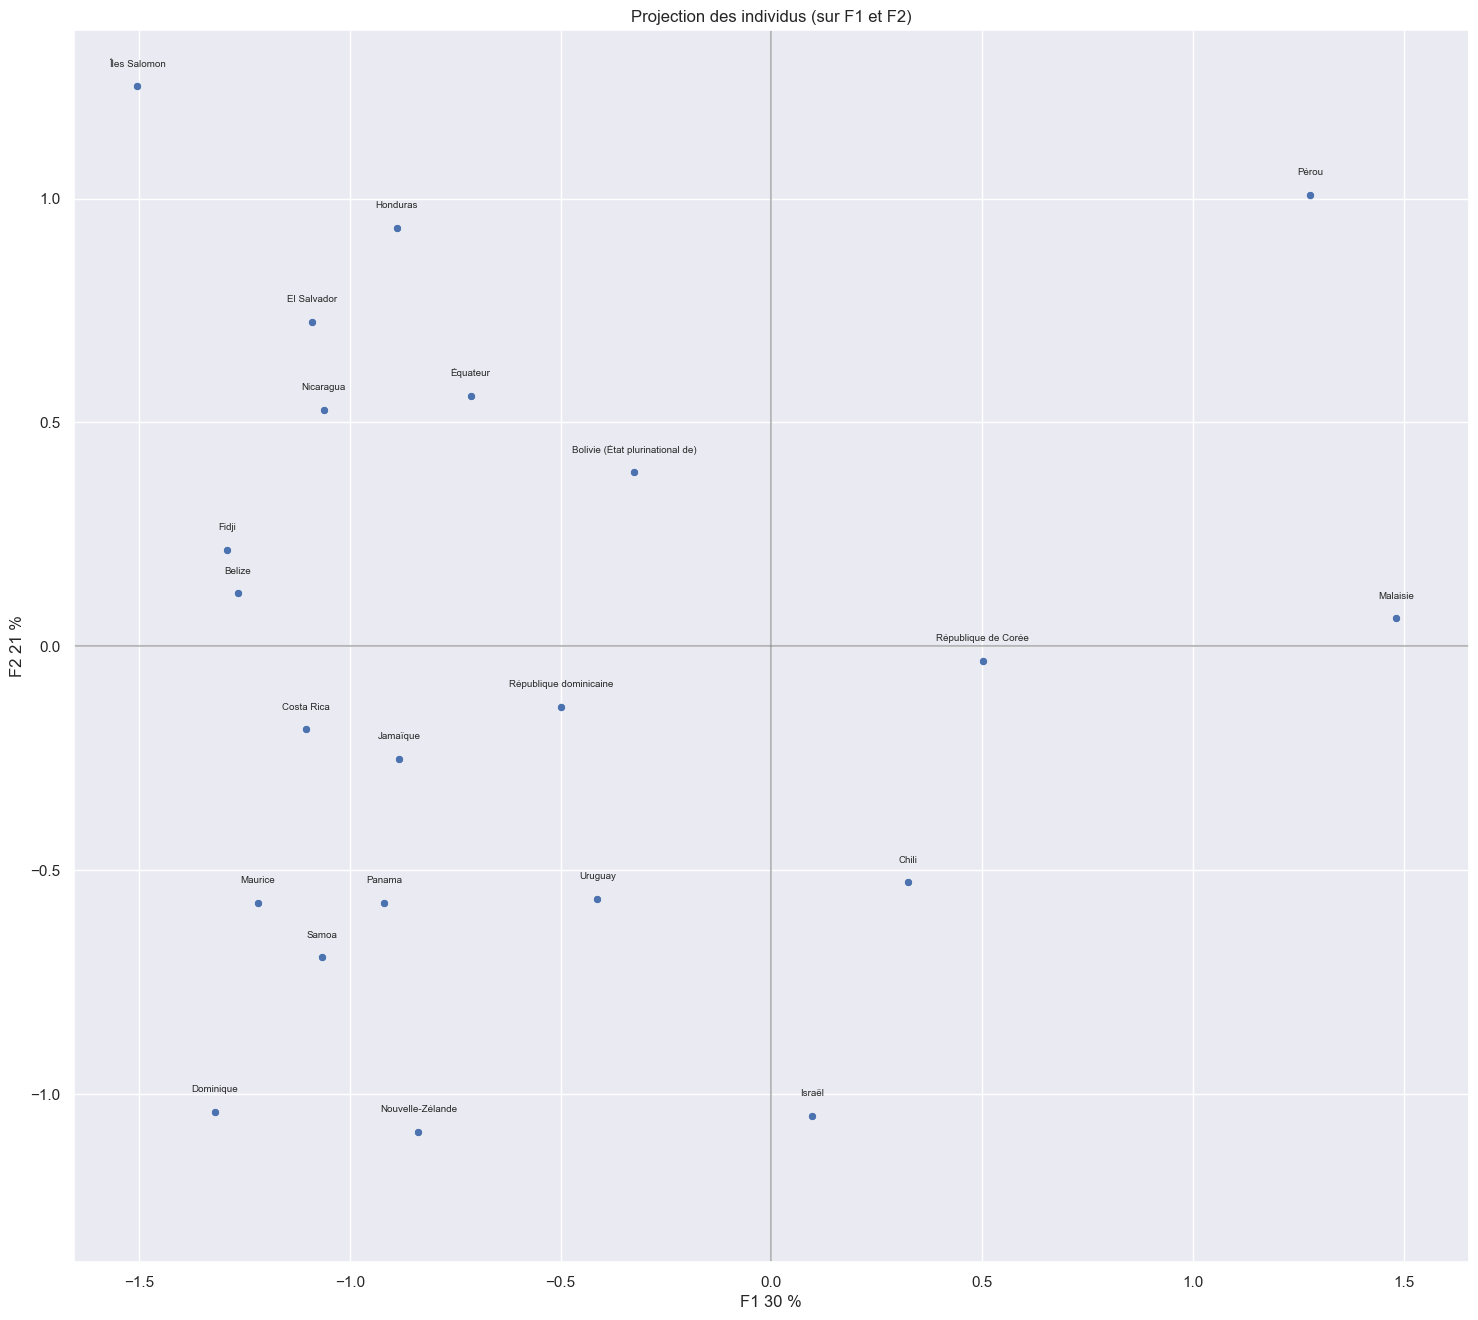

In [75]:
display_factorial_planes(X_proj[labels_km == 0], 
                        (0, 1), 
                        pca,
                        labels=names[labels_km == 0],
                        figsize=(18,16))

In [76]:
print("Cluster 1:\n")

df_copy[df_copy['cluster_km'] == 1][['pays', 'continent']].sort_values('continent').head(50)

Cluster 1:



,pays,continent
48,Koweït,Asie
65,Oman,Asie
99,Émirats arabes unis,Asie
13,Bulgarie,Europe
88,Suède,Europe
86,Suisse,Europe
84,Slovénie,Europe
83,Slovaquie,Europe
75,Roumanie,Europe
73,Portugal,Europe


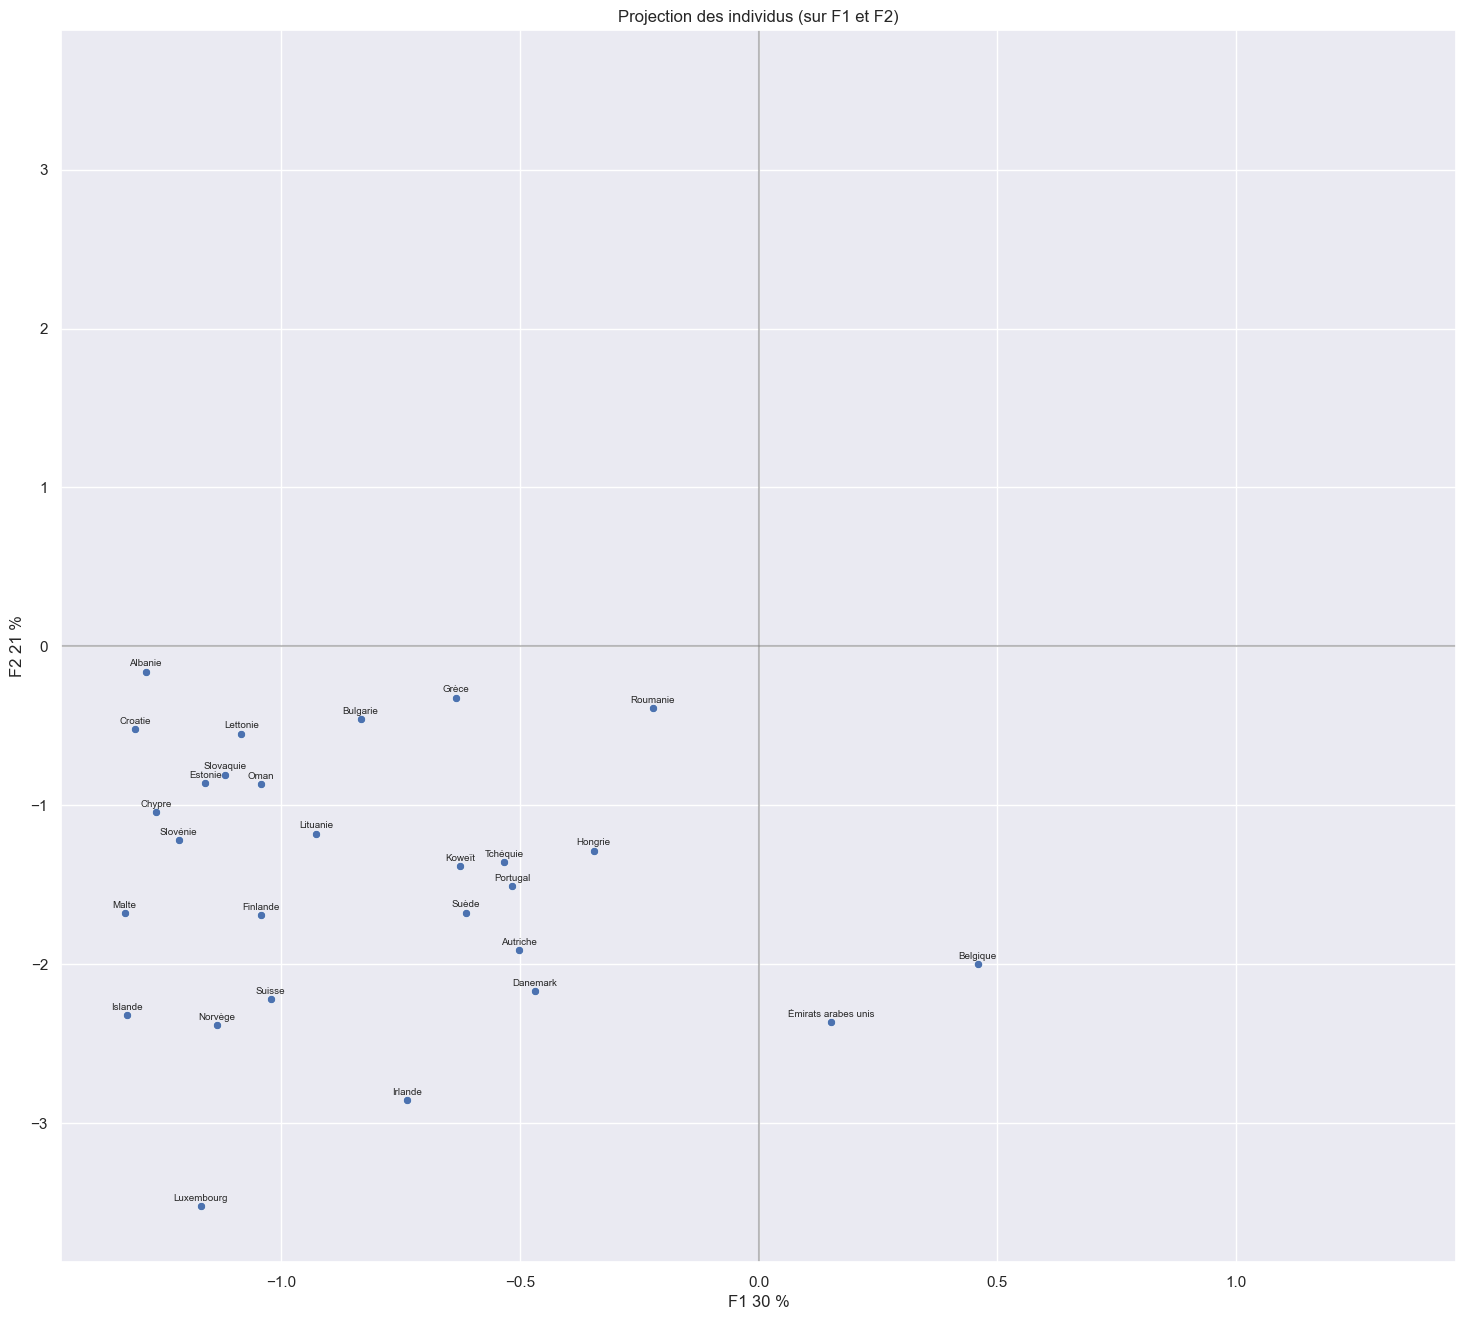

In [77]:
display_factorial_planes(X_proj[labels_km == 1], 
                        (0, 1), 
                        pca,
                        labels=names[labels_km == 1],
                        figsize=(18,16))

In [78]:
print("Cluster 2:\n")

df_copy[df_copy['cluster_km'] == 2][['pays', 'continent']].sort_values('continent').head(50)

Cluster 2:



,pays,continent
5,Argentine,Amérique
16,Canada,Amérique
91,Thaïlande,Asie
3,Allemagne,Europe
26,Espagne,Europe
42,Italie,Europe
70,Pays-Bas,Europe
72,Pologne,Europe
76,Royaume-Uni de Grande-Bretagne et d'Irlande du...,Europe
94,Turquie,Europe


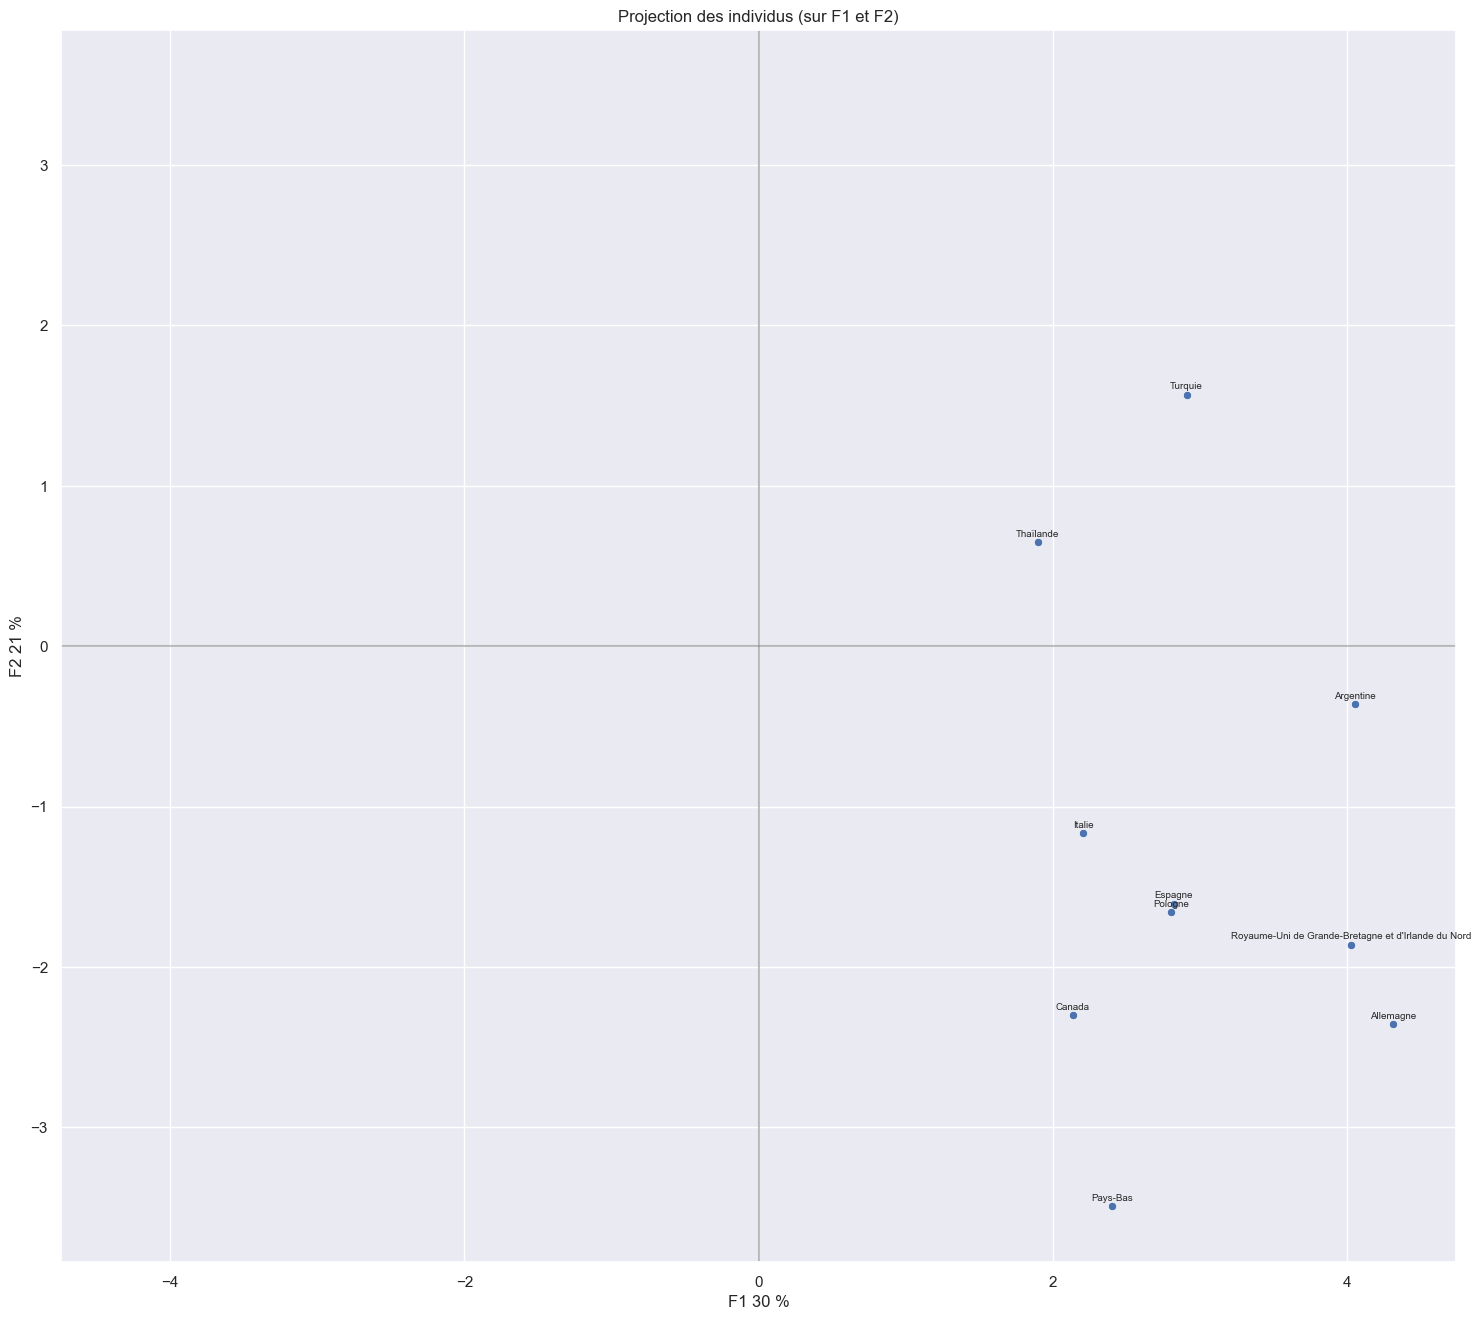

In [79]:
display_factorial_planes(X_proj[labels_km == 2], 
                        (0, 1), 
                        pca,
                        labels=names[labels_km == 2],
                        figsize=(18,16))

In [80]:
print("Cluster 3:\n")

df_copy[df_copy['cluster_km'] == 3][['pays', 'continent']].sort_values('continent').head(50)

Cluster 3:



,pays,continent
2,Algérie,Afrique
93,Tunisie,Afrique
92,Togo,Afrique
89,Sénégal,Afrique
82,Sierra Leone,Afrique
77,Rwanda,Afrique
66,Ouganda,Afrique
62,Nigéria,Afrique
61,Niger,Afrique
59,Namibie,Afrique


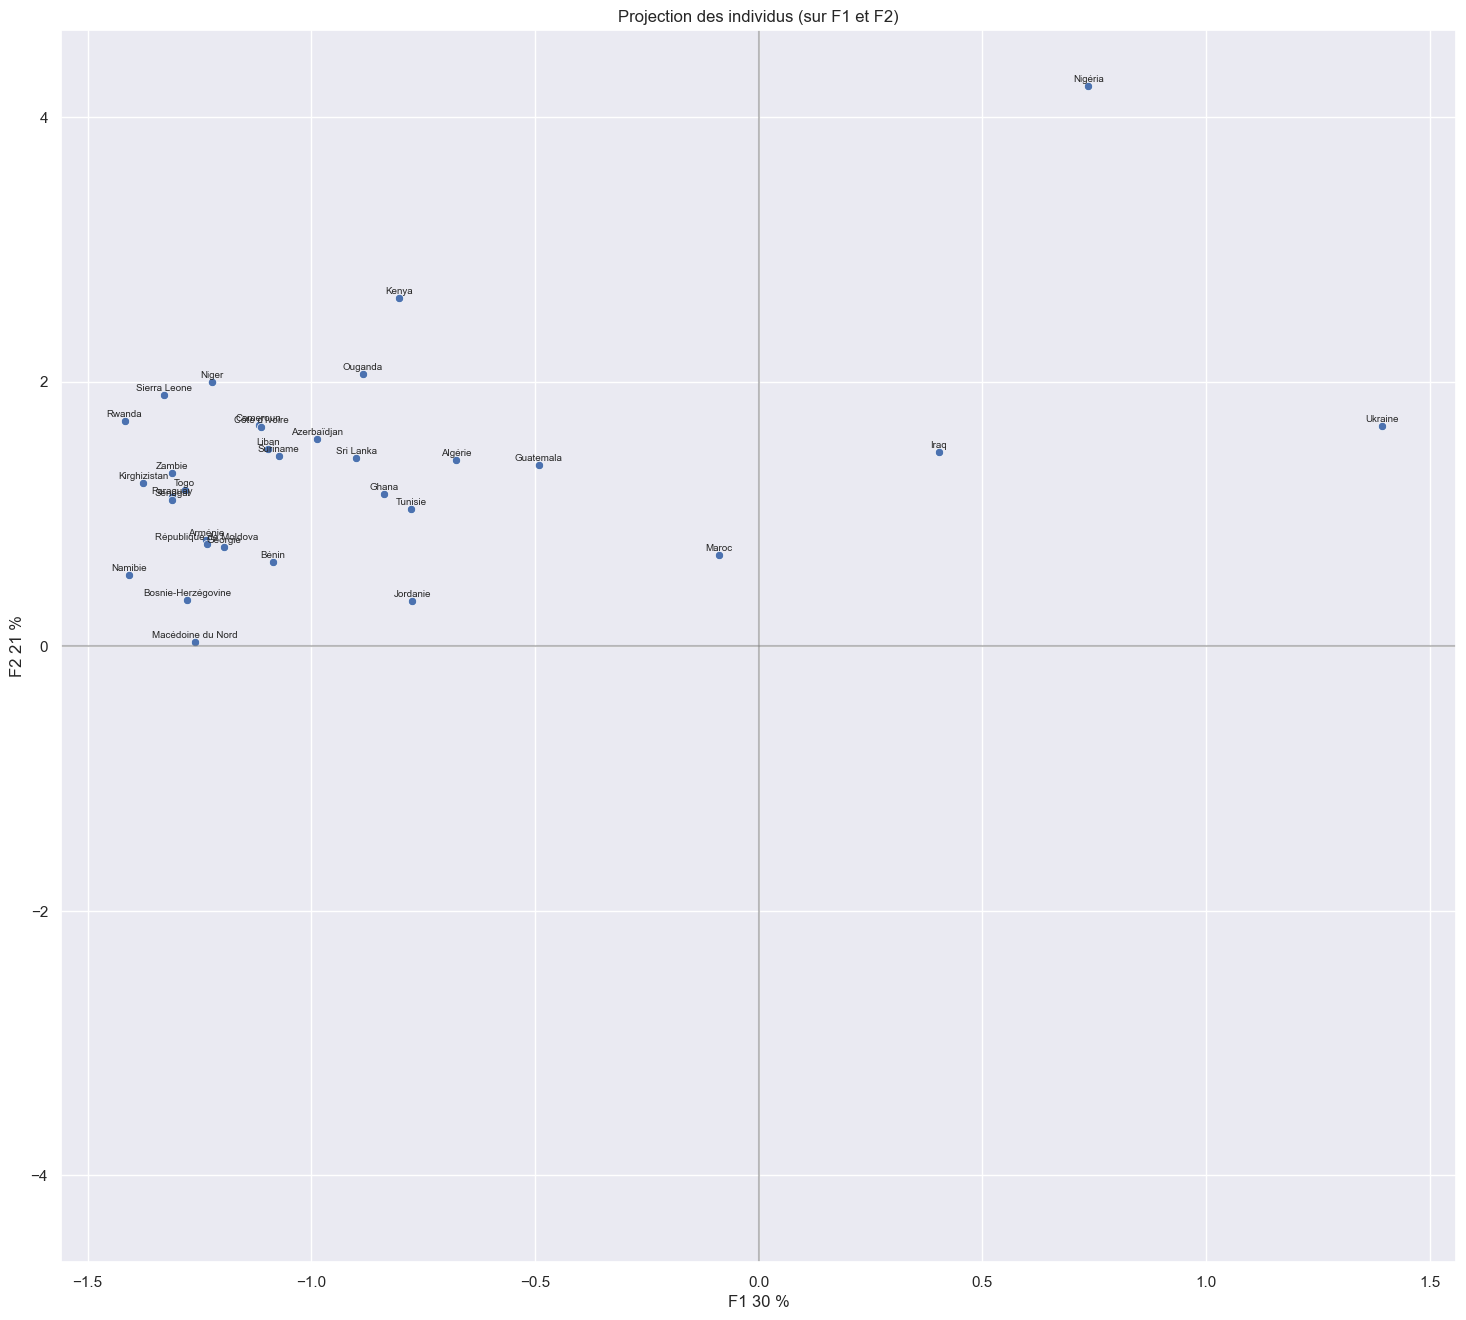

In [81]:
display_factorial_planes(X_proj[labels_km == 3], 
                        (0, 1), 
                        pca,
                        labels=names[labels_km == 3],
                        figsize=(18,16))

In [82]:
print("Cluster 4:\n")

df_copy[df_copy['cluster_km'] == 4][['pays', 'continent']].sort_values('continent').head(50)

Cluster 4:



,pays,continent
0,Afrique du Sud,Afrique
19,Colombie,Amérique
58,Mexique,Amérique
4,Arabie saoudite,Asie
30,Fédération de Russie,Asie
37,Indonésie,Asie
44,Japon,Asie
67,Pakistan,Asie
71,Philippines,Asie
97,Viet Nam,Asie


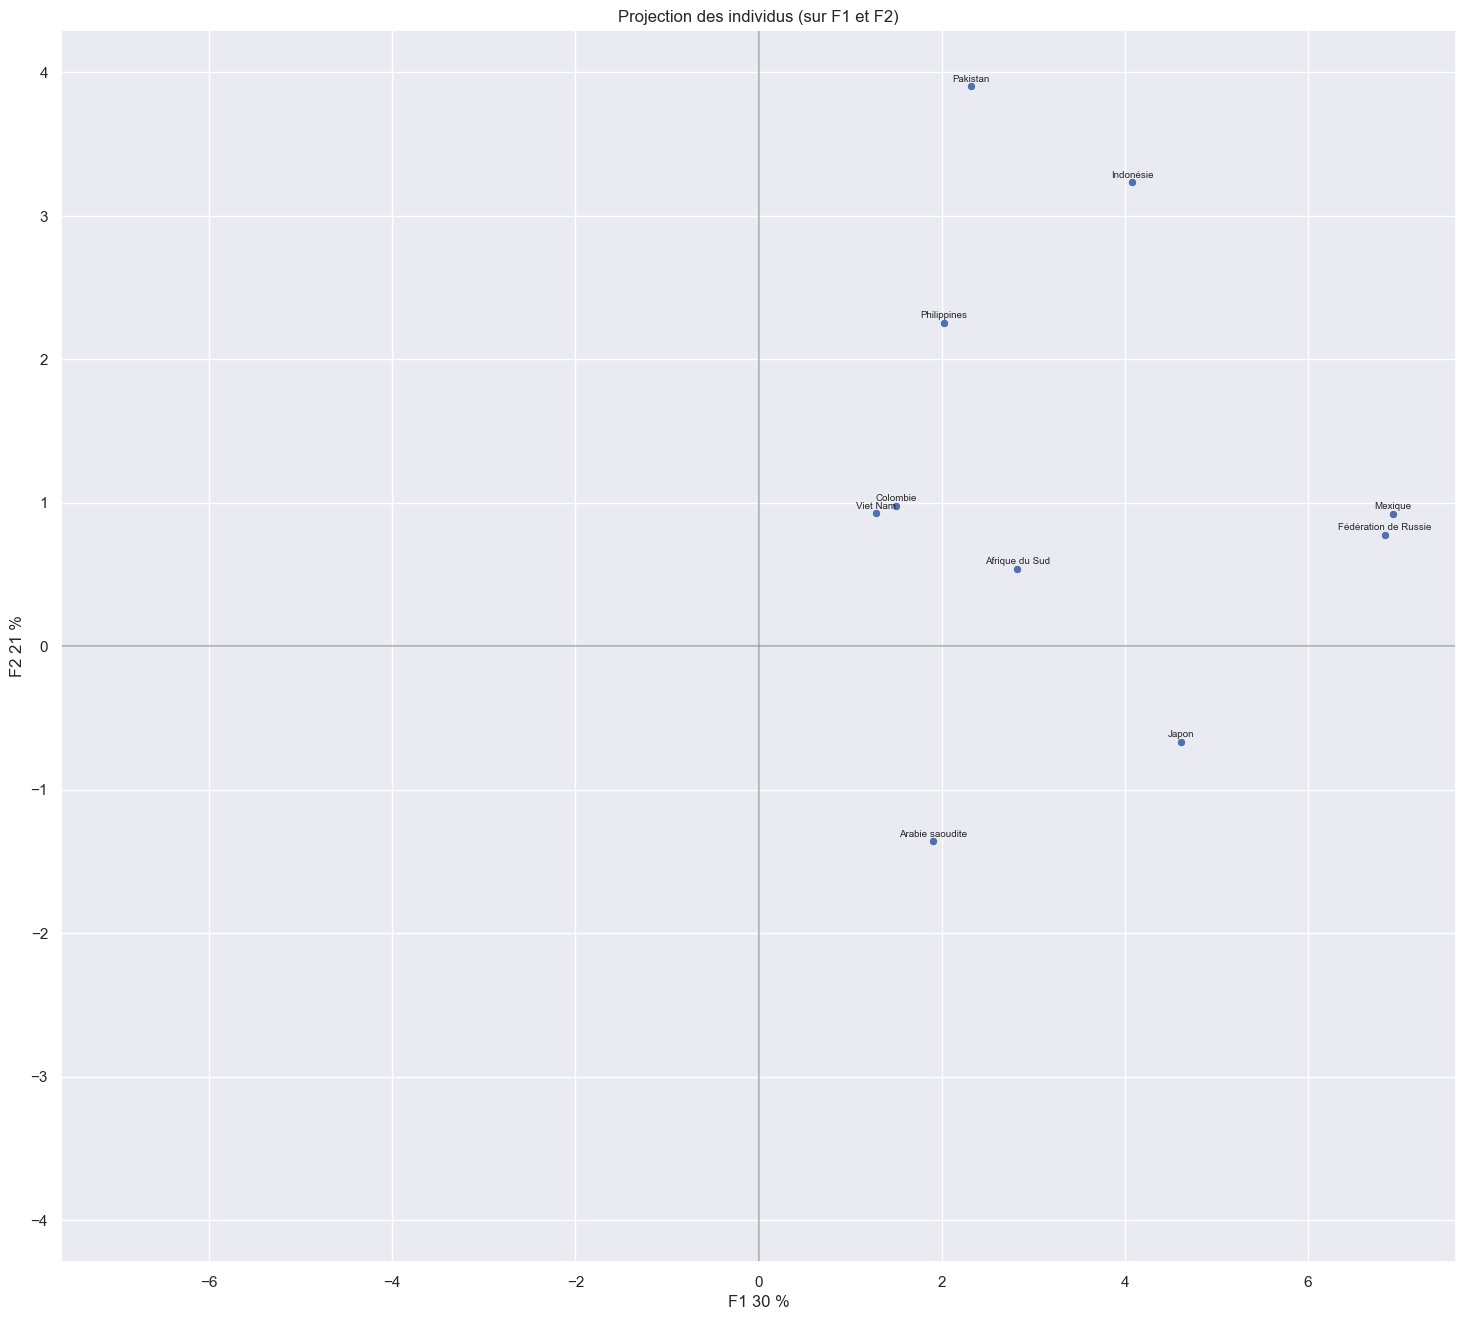

In [83]:
display_factorial_planes(X_proj[labels_km == 4], 
                        (0, 1), 
                        pca,
                        labels=names[labels_km == 4],
                        figsize=(18,16))

### 5.2.3 Projection des centroïdes

In [86]:
centroids_proj = pd.DataFrame(centroids,
                              columns=["F1", "F2", "F3", "F4", "F5", "F6"],
                              index=["cluster_0", "cluster_1", "cluster_2", "cluster_3", "cluster_4"])

In [87]:
centroids_proj.round(2)

,F1,F2,F3,F4,F5,F6
cluster_0,-0.58,-0.04,1.57,0.08,0.32,-0.30
cluster_1,-0.82,-1.46,-0.47,-0.10,-0.41,0.24
cluster_2,2.96,-1.26,-0.94,1.03,0.59,-0.96
cluster_3,-0.89,1.34,-0.61,0.05,0.09,0.15
cluster_4,3.43,1.15,0.77,-1.07,-0.43,0.47


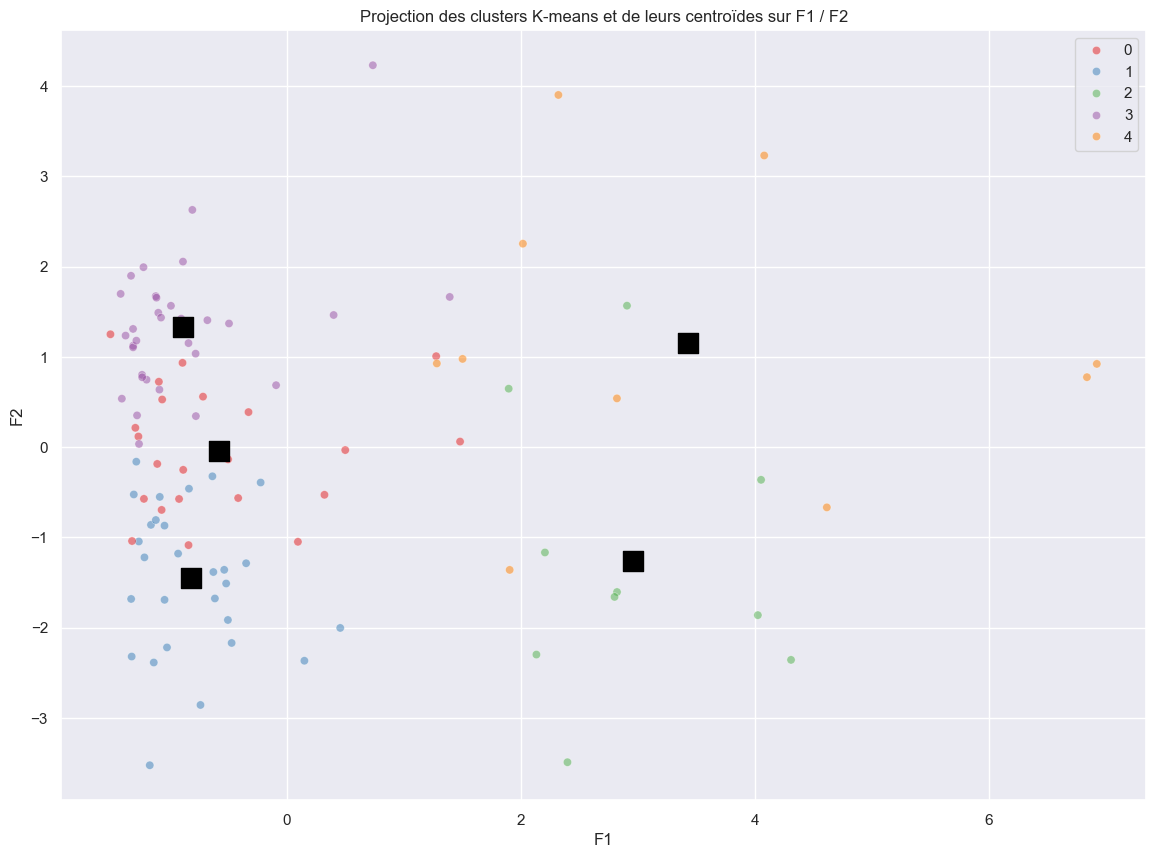

In [88]:
fig, ax = plt.subplots(1, 1, figsize=(14, 10))

sns.scatterplot(x=X_proj[:, 0], y=X_proj[:, 1], hue=labels_km, palette="Set1", alpha=0.5, ax=ax)

ax.scatter(centroids_proj["F1"], centroids_proj["F2"], marker="s", c="black", s=200)

ax.set_title("Projection des clusters K-means et de leurs centroïdes sur F1 / F2")

ax.set_xlabel("F1")
ax.set_ylabel("F2")

plt.show()

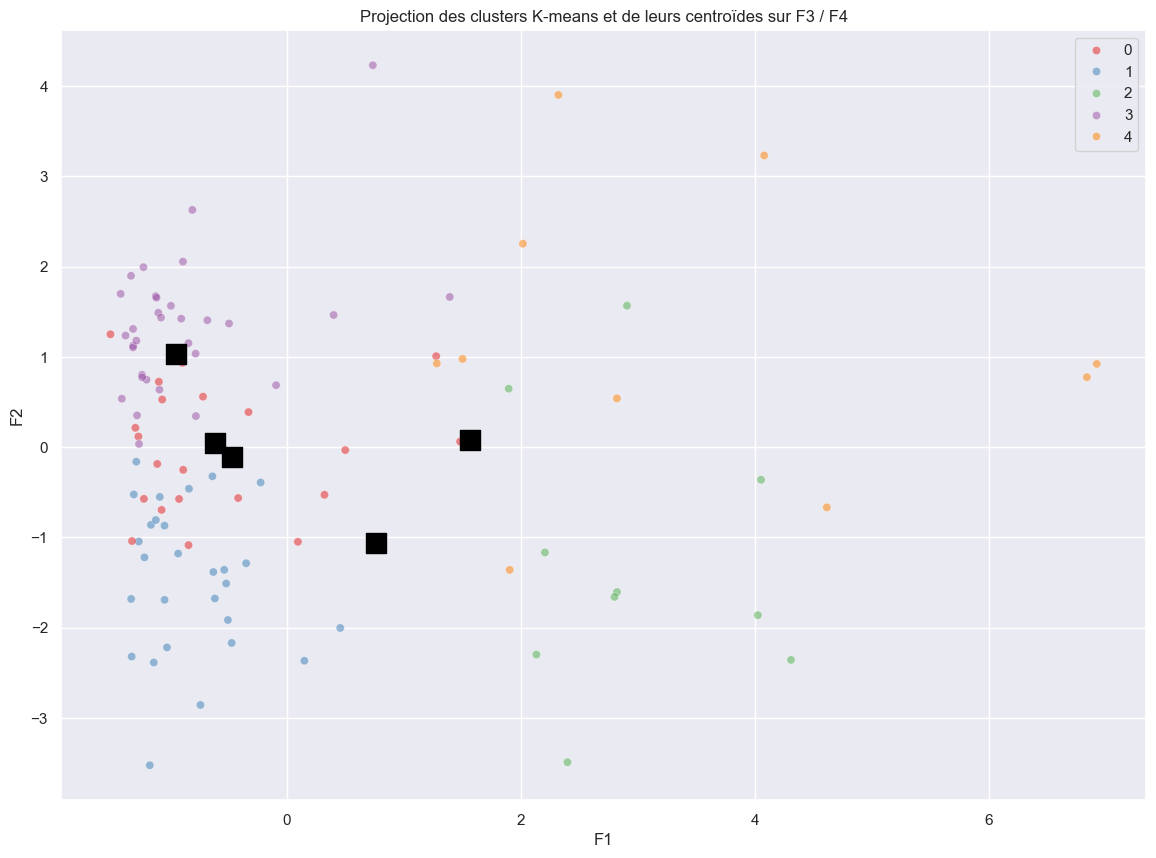

In [89]:
fig, ax = plt.subplots(1, 1, figsize=(14, 10))

sns.scatterplot(x=X_proj[:, 0], y=X_proj[:, 1], hue=labels_km, palette="Set1", alpha=0.5, ax=ax)

ax.scatter(centroids_proj["F3"], centroids_proj["F4"], marker="s", c="black", s=200)

ax.set_title("Projection des clusters K-means et de leurs centroïdes sur F3 / F4")

ax.set_xlabel("F1")
ax.set_ylabel("F2")

plt.show()

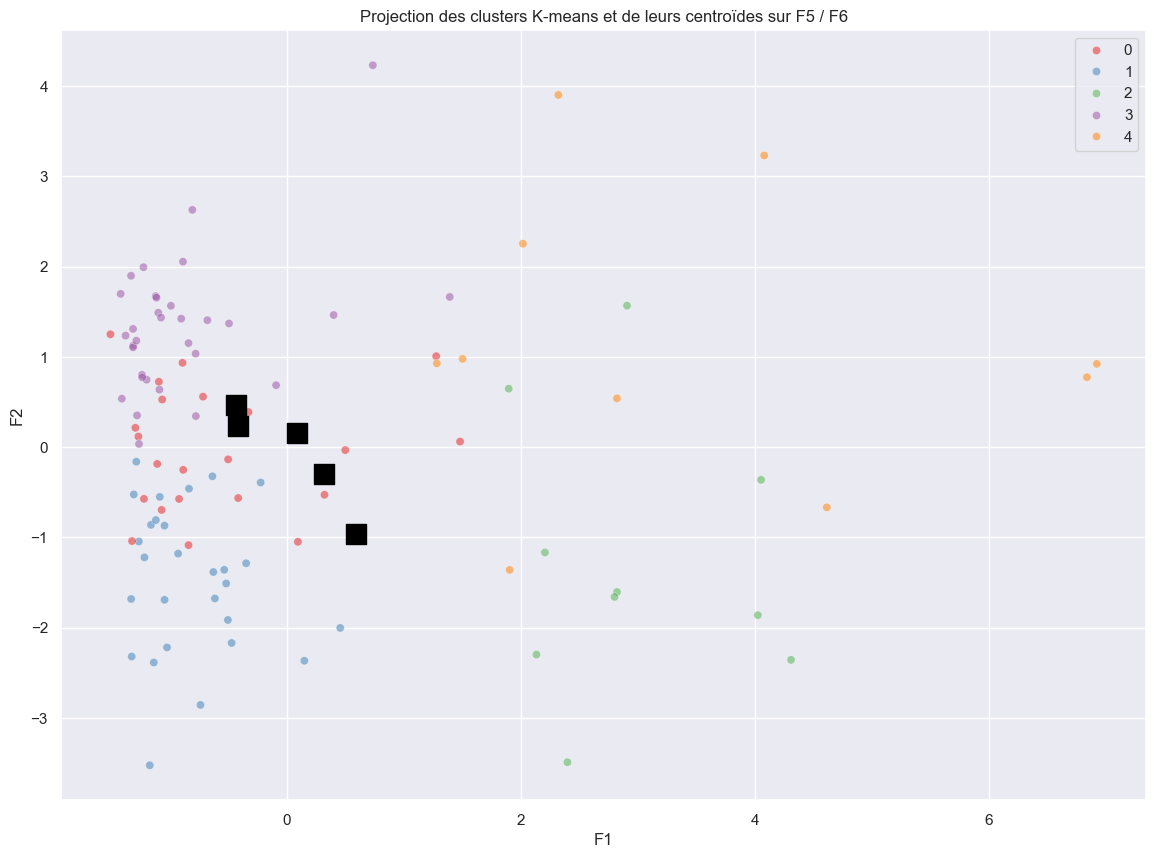

In [90]:
fig, ax = plt.subplots(1, 1, figsize=(14, 10))

sns.scatterplot(x=X_proj[:, 0], y=X_proj[:, 1], hue=labels_km, palette="Set1", alpha=0.5, ax=ax)

ax.scatter(centroids_proj["F5"], centroids_proj["F6"], marker="s", c="black", s=200)

ax.set_title("Projection des clusters K-means et de leurs centroïdes sur F5 / F6")

ax.set_xlabel("F1")
ax.set_ylabel("F2")

plt.show()

### 5.2.4 Comparaison des différents clusters

In [91]:
df_result = df.copy()

df_result['cluster_cah'] = labels_cah
df_result['cluster_kmeans'] = labels_km

df_result.head()

,pays,volailles_dispo_alimentaire_kcal_pers_j,volailles_dispo_interieure,volailles_exportations,volailles_importations,volailles_production,population,continent,stabilite_politique,distance,pib_habitant,surface_bio_1000_ha,inflation_alimentaire,cluster_cah,cluster_kmeans
0,Afrique du Sud,143.0,2118.0,63.0,514.0,1667.0,57009756,Afrique,-0.28,9353.5520,14574.0,41.38,6.90,1,4
1,Albanie,85.0,47.0,0.0,38.0,13.0,2884169,Europe,0.38,1603.5340,15359.0,0.55,3.91,3,1
2,Algérie,22.0,277.0,0.0,2.0,275.0,41389189,Afrique,-0.92,1340.3900,15428.0,0.77,5.04,5,3
3,Allemagne,71.0,1739.0,646.0,842.0,1514.0,82658409,Europe,0.59,439.8984,61866.0,1138.30,2.76,1,2
4,Arabie saoudite,151.0,1435.0,10.0,722.0,616.0,33101178,Asie,-0.58,4694.5000,57943.0,17.10,-0.82,1,4


Moyenne des différentes varaibles par clusters obtenu grace à la classification ascendante hiérarchique:

In [92]:
profil_clusters_cah = df_result.groupby('cluster_cah')[features].mean().round(2)
profil_clusters_cah

,volailles_dispo_alimentaire_kcal_pers_j,volailles_dispo_interieure,volailles_exportations,volailles_importations,volailles_production,population,stabilite_politique,distance,pib_habitant,surface_bio_1000_ha,inflation_alimentaire
cluster_cah,,,,,,,,,,,
1,80.44,1865.22,109.67,340.78,1693.67,99370571.11,-0.57,6729.52,26975.00,279.78,4.72
2,89.67,962.11,518.11,166.44,1336.78,36336787.78,0.45,4636.35,43072.11,1219.37,3.43
3,89.50,155.39,38.29,73.89,137.07,5934403.93,0.72,1900.12,51313.54,171.02,1.93
4,118.71,179.59,8.94,19.59,186.41,5839054.41,0.38,10719.80,16620.00,35.74,1.15
5,36.50,136.23,2.13,41.97,97.07,16155265.70,-0.52,4757.85,9974.87,43.96,6.36


Moyenne des différentes varaibles par clusters obtenu grace à la méthode K-means:

In [93]:
profil_clusters_km = df_result.groupby('cluster_kmeans')[features].mean().round(2)
profil_clusters_km

,volailles_dispo_alimentaire_kcal_pers_j,volailles_dispo_interieure,volailles_exportations,volailles_importations,volailles_production,population,stabilite_politique,distance,pib_habitant,surface_bio_1000_ha,inflation_alimentaire
cluster_kmeans,,,,,,,,,,,
0,115.95,350.91,9.50,27.32,357.18,1.020863e+07,0.31,10280.77,20336.73,138.93,1.50
1,82.71,138.11,61.61,85.96,131.14,6.047829e+06,0.77,1792.28,51870.04,173.80,1.97
2,99.20,1412.10,543.80,278.10,1705.50,5.426770e+07,0.17,3353.10,44100.60,1119.28,4.45
3,36.72,165.56,10.53,43.12,135.12,2.250059e+07,-0.61,4671.34,10123.53,51.91,6.98
4,84.00,2271.80,21.60,412.40,1952.70,1.209162e+08,-0.57,8165.95,22703.60,194.84,2.44


On va à présent standartiser les différents clusters obtenus via nos deux méthodes, pour pouvoir les visualiser dans une heatmap.

Heatmap CAH:

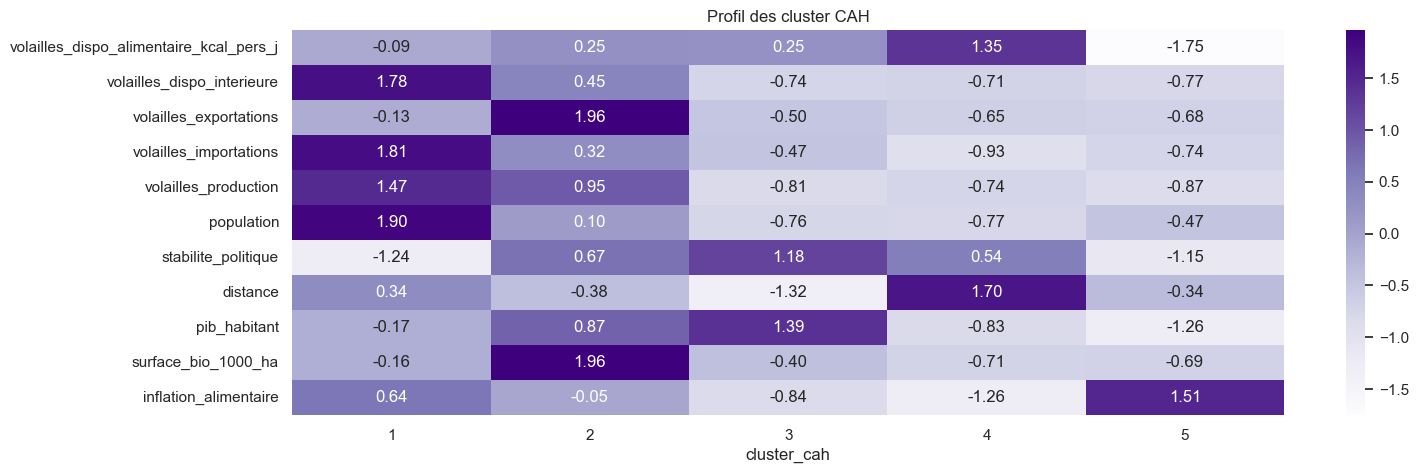

In [94]:
profil_scaled_cah = pd.DataFrame(
    scaler.fit_transform(profil_clusters_cah),
    columns=features,
    index=profil_clusters_cah.index
)

fig, ax = plt.subplots(1,1, figsize=(16, 5))
sns.heatmap(profil_scaled_cah.T, annot=True, fmt='.2f', cmap='Purples', ax=ax)


plt.title('Profil des cluster CAH')

plt.show()

Heatmap K-means:

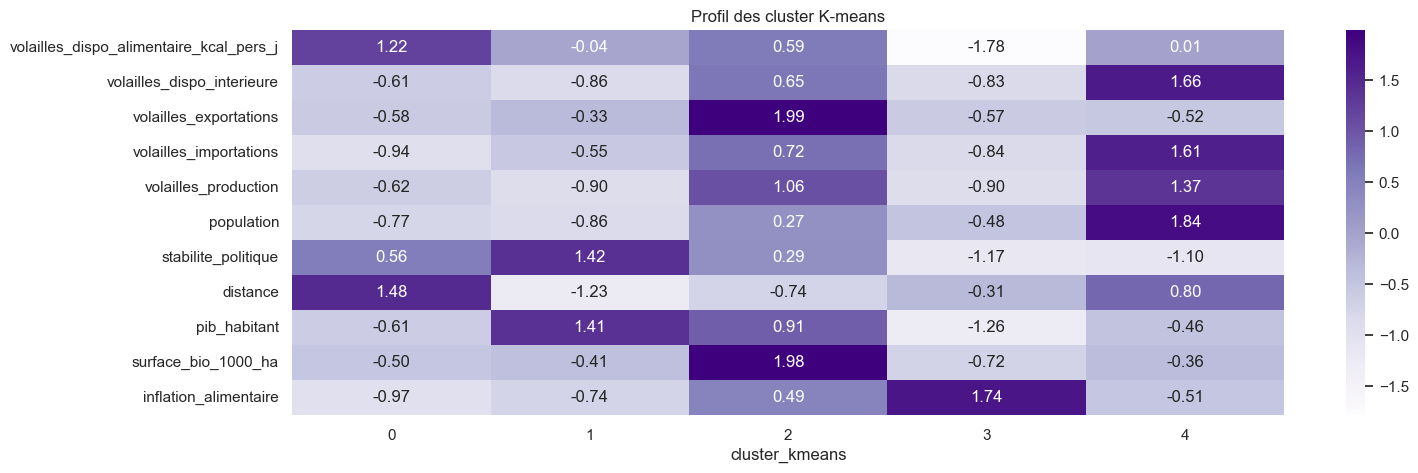

In [95]:
profil_scaled_km = pd.DataFrame(
    scaler.fit_transform(profil_clusters_km),
    columns=features,
    index=profil_clusters_km.index
)

fig, ax = plt.subplots(1,1, figsize=(16, 5))
sns.heatmap(profil_scaled_km.T, annot=True, fmt='.2f', cmap='Purples', ax=ax)

plt.title('Profil des cluster K-means')

plt.show()

Illustrons à présent la distribution de nos différents clusters au sein des différentes variables dans des boxplots:

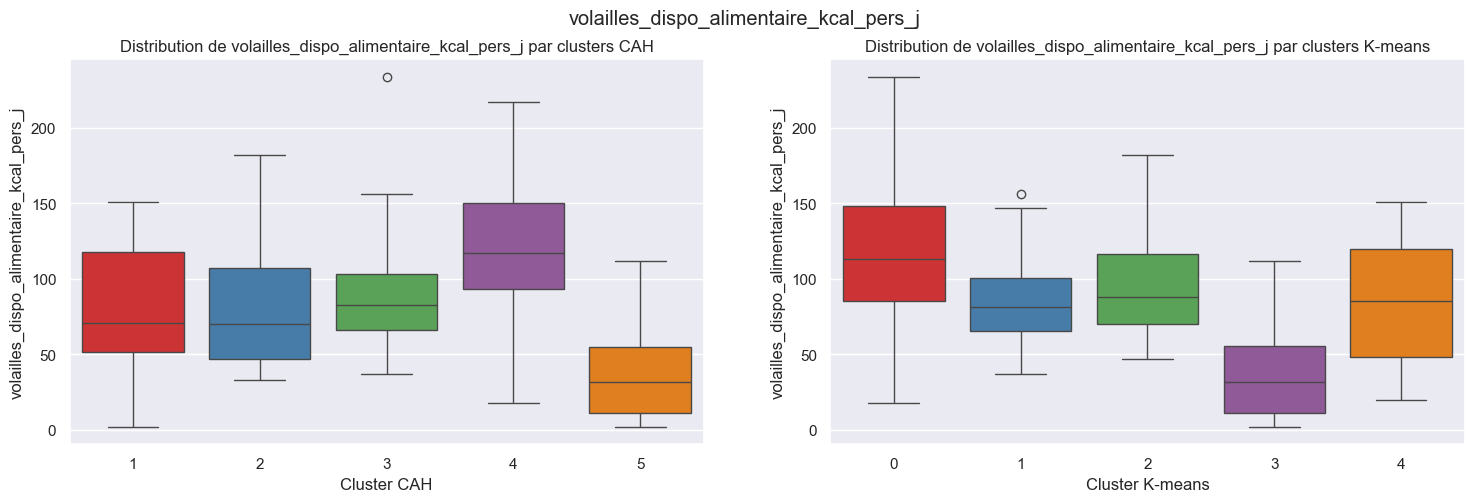

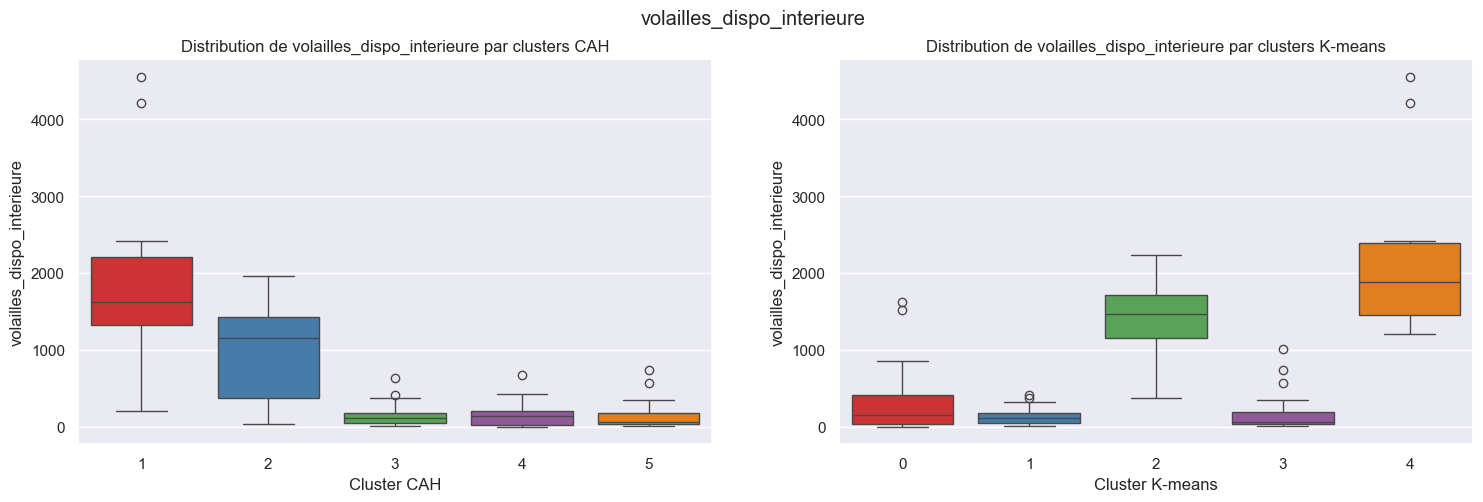

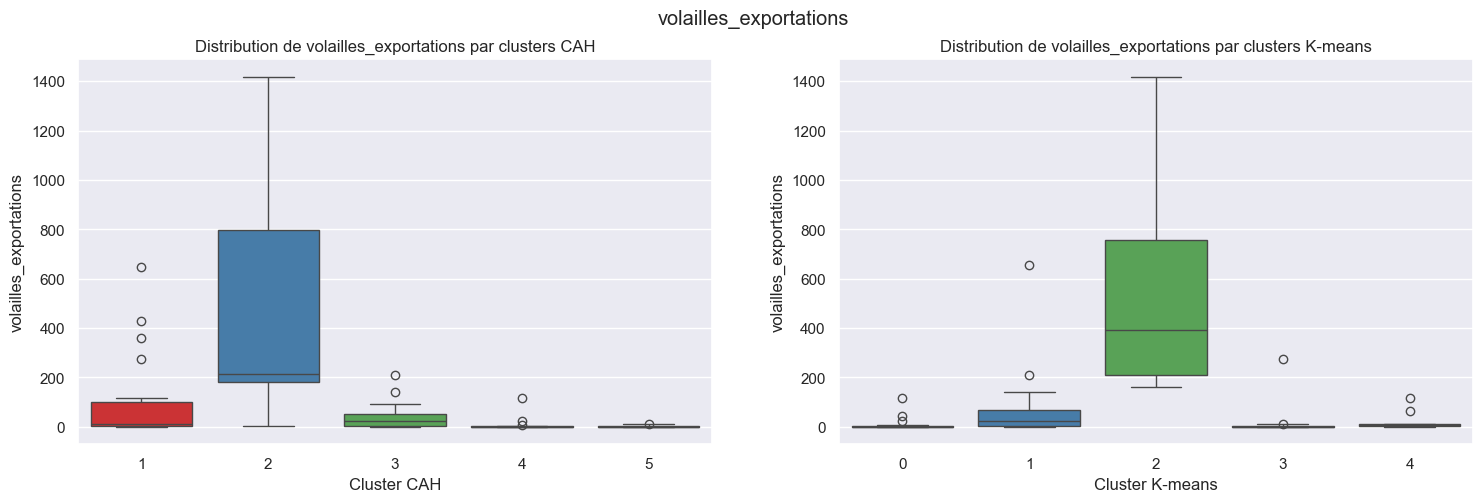

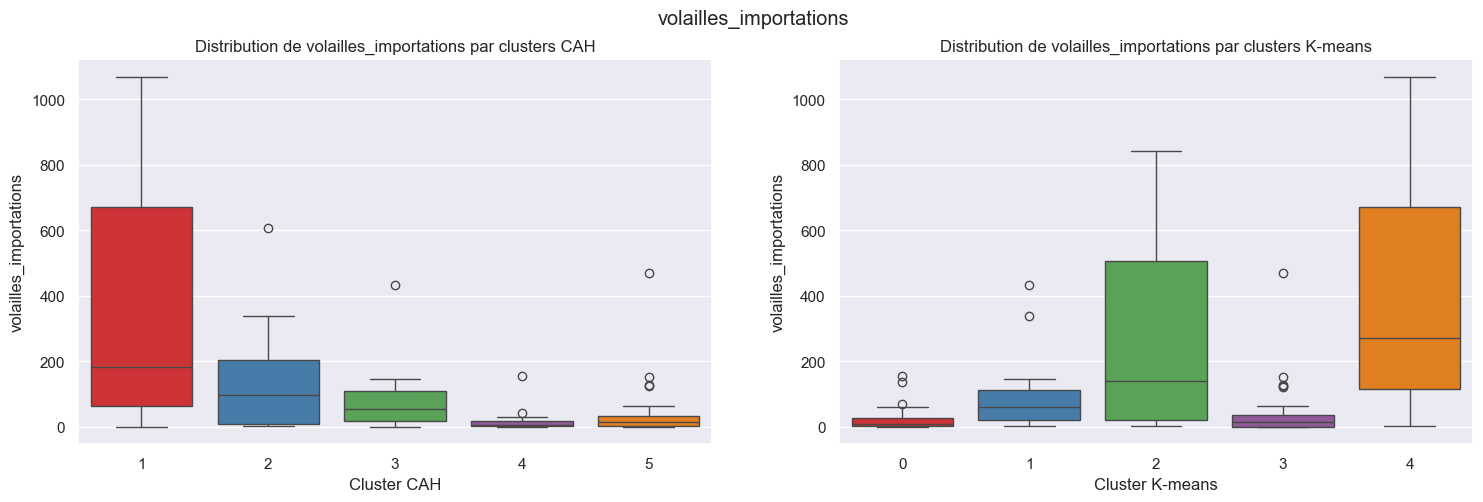

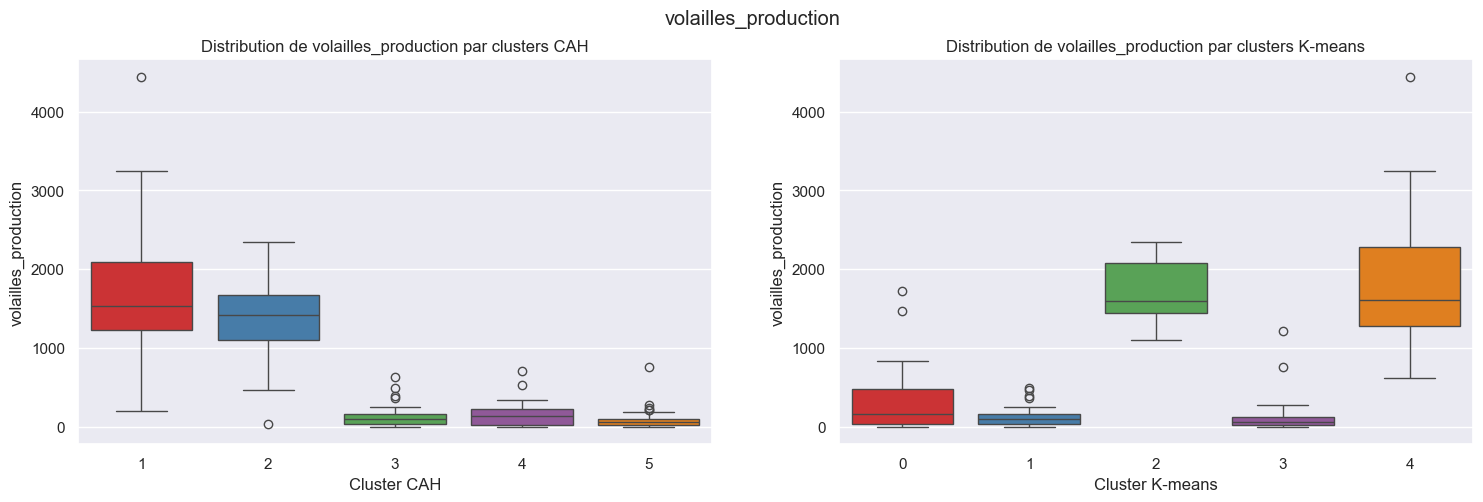

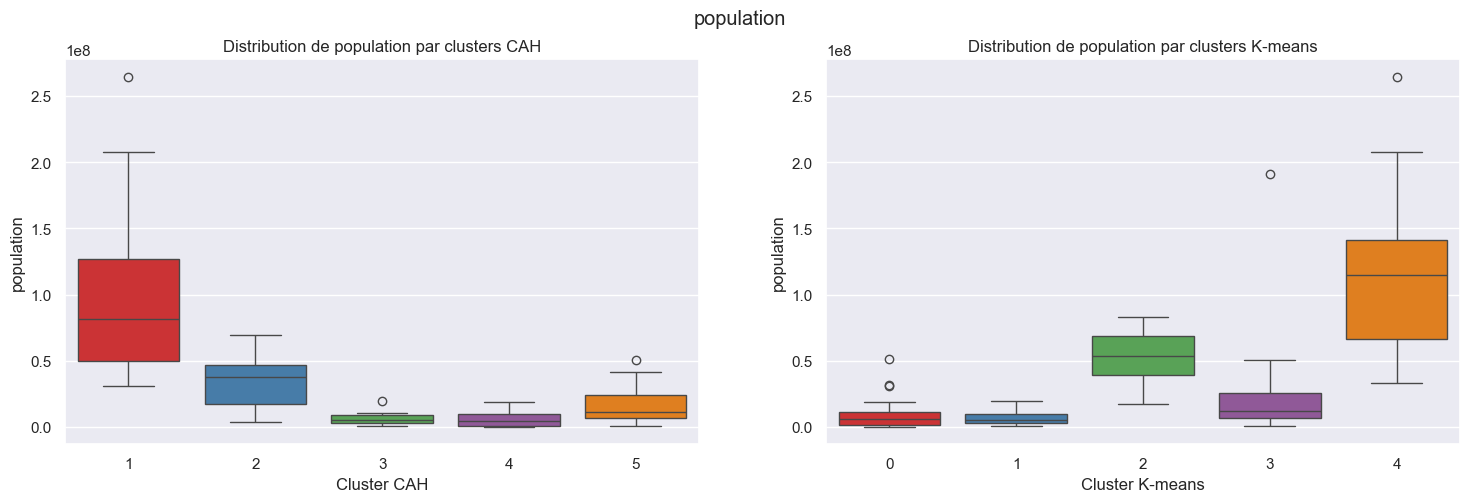

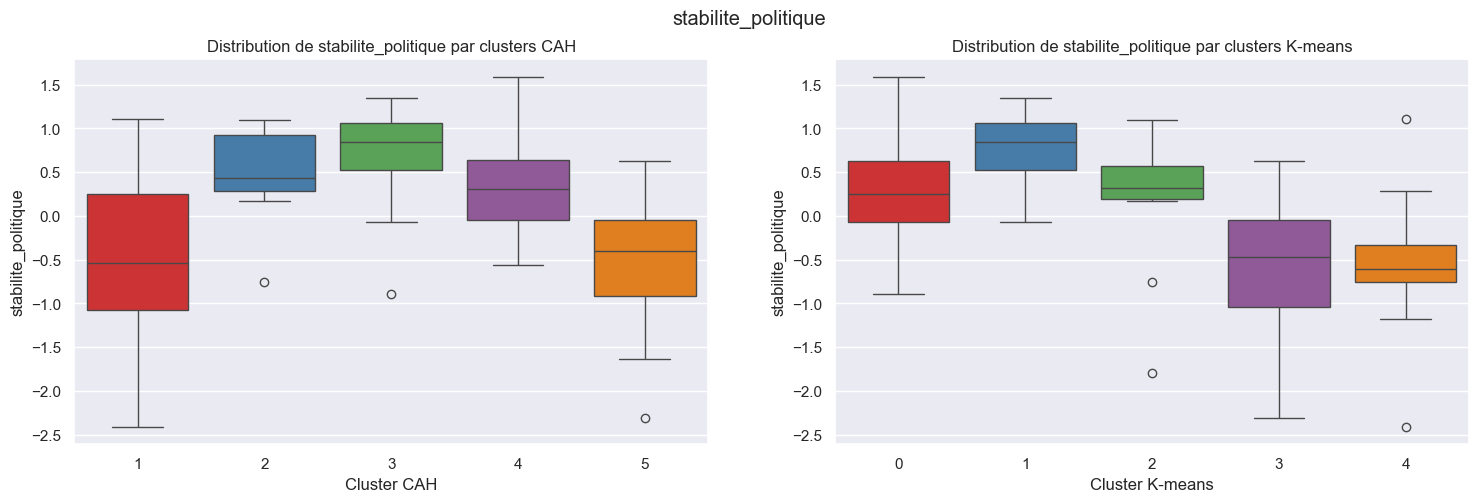

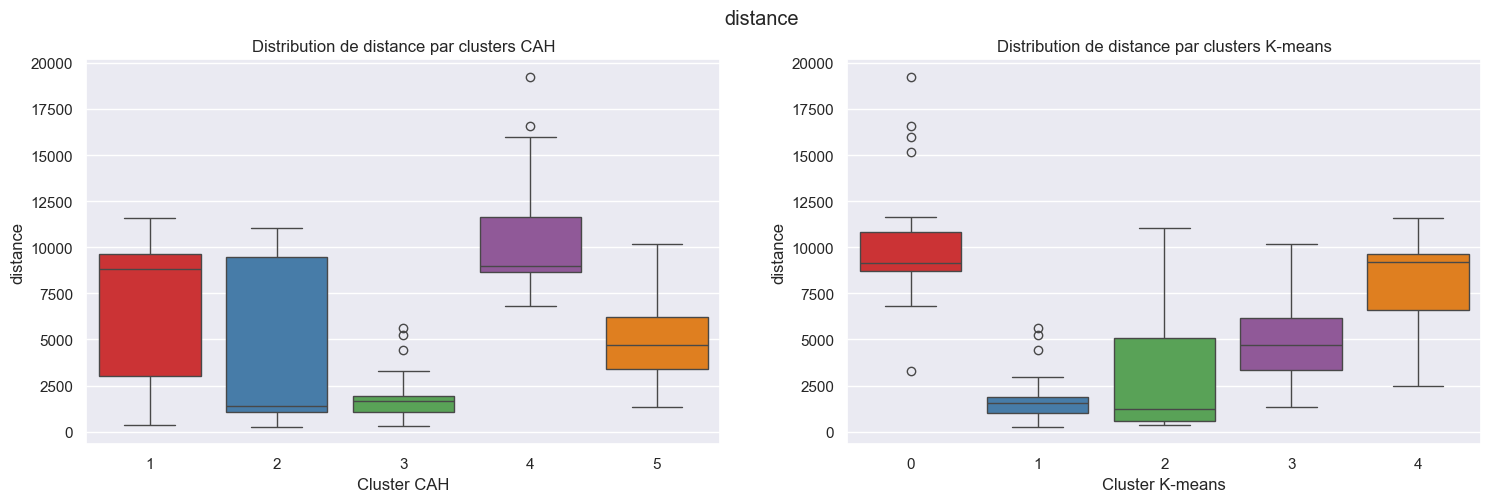

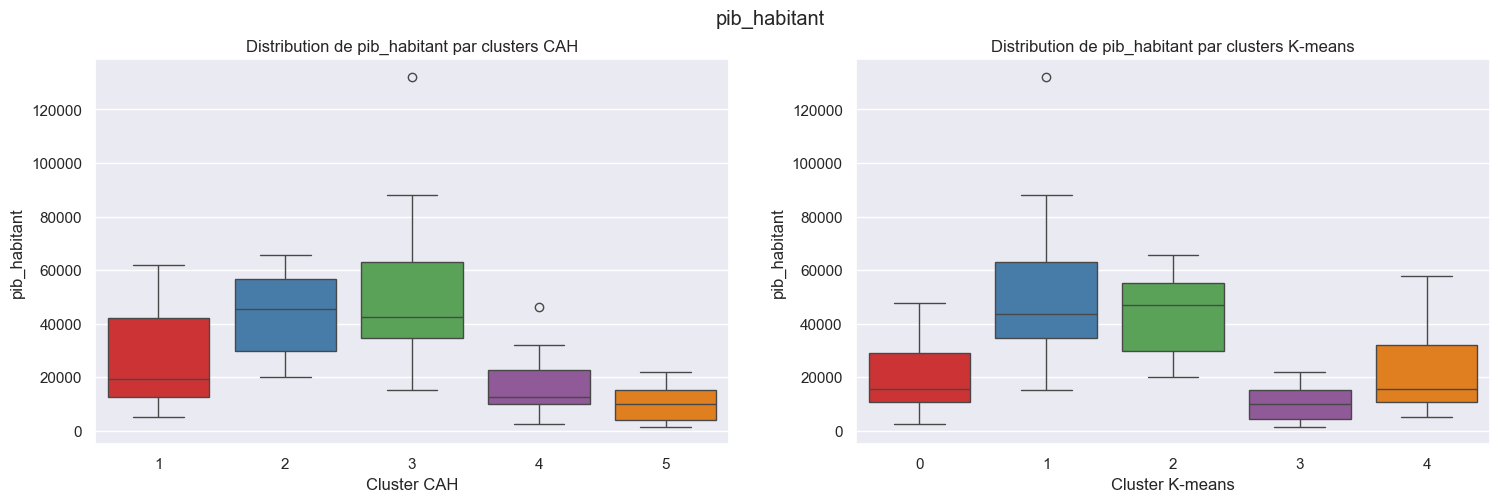

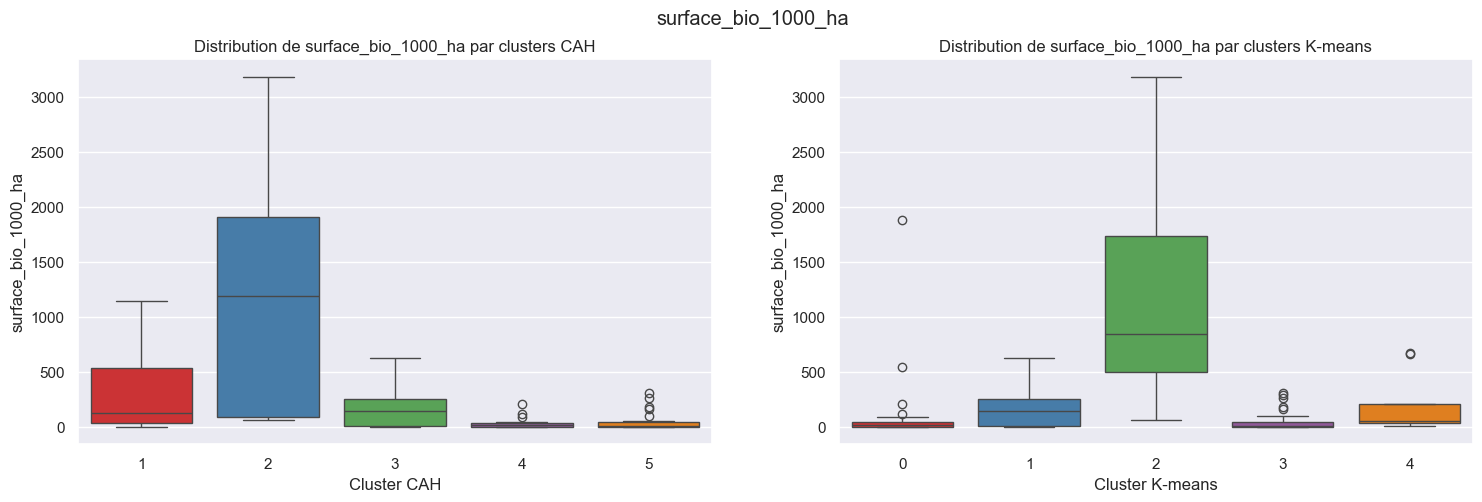

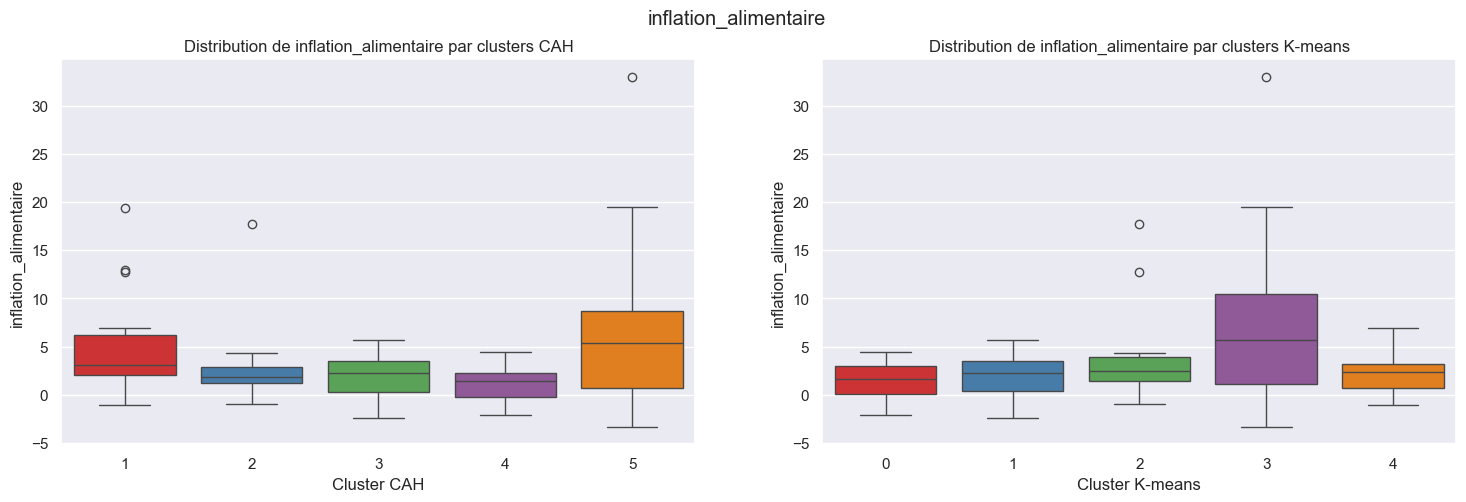

In [97]:
for feature in features:
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    
    sns.boxplot(
        data=df_result,
        x='cluster_cah',
        y=feature,
        hue='cluster_cah',
        palette='Set1',
        legend=False,
        ax=axes[0]
    )
    
    axes[0].set_title(f'Distribution de {feature} par clusters CAH')
    axes[0].set_xlabel('Cluster CAH')
    
    sns.boxplot(
        data=df_result,
        x='cluster_kmeans',
        y=feature,
        hue='cluster_kmeans',
        palette='Set1',
        legend=False,
        ax=axes[1]
    )
    
    axes[1].set_title(f'Distribution de {feature} par clusters K-means')
    axes[1].set_xlabel('Cluster K-means')
    
    plt.suptitle(f'{feature}')

    plt.show()

On observe que cluster 4 obtenu avec la méthode CAH et le cluster 2 obtenu avec la méthode K-means, soit les clusters rassemblant les profils des pays qui nous semblaient les plus intéressants, présentent tout les deux des distributions extrêmements similaies.
- les deux groupes présentent une disponibilité alimentaire par personne moyenne par rapport aux autres clusters
- leurs disponibilités intérieures en viande de volaille est assez faibles si on les compare aux autres groupes/outliers
- pour ce qui est des exportations, quelques outliers sont présents au sein même de ces clusters, mais ils affichent des valeurs assez faibles
- ce sont des importateurs assez importants
- là encore, si on les compare aux autres clusters, leurs niveaux de production est assez faible
- ils ont peu d'habitants
- ce sont les plus stables politiquement
- ce sont les pays situés le plus près de la France
- le pib par habitant y est très élevé
- les pays les composants ont subi une inflation alimentaire modérée en 2017

Les deux clusters, le 4 obtenu grâce à la CAH, et le 2 résultant de la méthode des K-means, constituent des groupements de pays qu'il serait pertinent de cibler pour l'exportation de nos poulets.

In [100]:
profil_clprofil_clusters_cah = df_result.groupby('cluster_cah')[features].mean().round(2)
print(profil_clprofil_clusters_cah)

             volailles_dispo_alimentaire_kcal_pers_j  \
cluster_cah                                            
1                                              80.44   
2                                              89.67   
3                                              89.50   
4                                             118.71   
5                                              36.50   

             volailles_dispo_interieure  volailles_exportations  \
cluster_cah                                                       
1                               1865.22                  109.67   
2                                962.11                  518.11   
3                                155.39                   38.29   
4                                179.59                    8.94   
5                                136.23                    2.13   

             volailles_importations  volailles_production   population  \
cluster_cah                                                    

In [102]:
profil_clusters_km = df_result.groupby('cluster_kmeans')[features].mean().round(2)
print(profil_clusters_km)

                volailles_dispo_alimentaire_kcal_pers_j  \
cluster_kmeans                                            
0                                                115.95   
1                                                 82.71   
2                                                 99.20   
3                                                 36.72   
4                                                 84.00   

                volailles_dispo_interieure  volailles_exportations  \
cluster_kmeans                                                       
0                                   350.91                    9.50   
1                                   138.11                   61.61   
2                                  1412.10                  543.80   
3                                   165.56                   10.53   
4                                  2271.80                   21.60   

                volailles_importations  volailles_production    population  \
cluster_kmeans   